# Load Libraries and Data

In [1]:
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Dataset

from PIL import Image
import os
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

from sklearn.utils import shuffle
from sklearn.model_selection import train_test_split,cross_val_score, cross_validate, RandomizedSearchCV, RepeatedKFold
from sklearn.metrics import r2_score, mean_squared_error,root_mean_squared_error,mean_absolute_error
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

import warnings
import numpy as np
import importlib

import seaborn as sns

import shap
import statsmodels.api as sm

from utils.neural_networks_utils import *

from utils.random_search_utils import random_search, get_best_hyper_parameters
from utils.data_loaders import load_dataset, load_images
from utils.utils import *


warnings.filterwarnings("ignore")

torch.manual_seed(42)
np.random.seed(42)
torch.backends.cudnn.deterministic = True

In [2]:
# Check and create directories for saving processed data
cur_dir = os.getcwd()
model_save_loc = os.path.join(cur_dir, "models/RF")
check_create_directory(model_save_loc)
result_save_loc = os.path.join(cur_dir, "results/RF")
check_create_directory(result_save_loc)


Directory already exists: /home/fdeniz2/ML Paper/models/RF
Directory already exists: /home/fdeniz2/ML Paper/results/RF


### Load Mean Data and Images

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

csv_file = "/home/fdeniz2/all_data/combined_visual_features.csv"
img_dir = "/home/fdeniz2/all_data/images_anonymized"
# load data
mean_data = pd.read_csv(csv_file)

mean_data_only_affect = mean_data[["image", "valence", "approach", "tense", "energetic"]]

# Change colunn names
fix_names_dataframe(mean_data)
number_of_visual_features =  len(mean_data[mean_data.columns.difference(["image", "valence", "Unnamed: 0", "room_type", "approach", "tense", "energetic"])].columns)

repeated_k_fold = RepeatedKFold(n_splits=5, n_repeats=1, random_state=42)


In [4]:
# Transform images before loading them
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                          std=[0.229, 0.224, 0.225]),

])

repeated_k_fold = RepeatedKFold(n_splits=5, n_repeats=6, random_state=42)


#### Extract Embeddings of DCNN

In [5]:
# Extract Embeddings of DCNN
convxnet_loaded = load_convx(device)
# Load Data
dataset = load_images(img_dir, transform = transform, multiple_folder =  True)
dataset = DataLoader(dataset, batch_size=216, shuffle=False, num_workers=4, pin_memory=True)

return_nodes = {"classifier.1": "layer"}

embeddings = extract_embeddings(convxnet_loaded, return_nodes, dataset, device)
mean_data_only_affect["image"] = [f"{i}.png" for i in mean_data_only_affect["image"]]

all_outputs = pd.merge(embeddings, mean_data_only_affect[mean_data_only_affect.columns.difference(["room_type", "Unnamed: 0"])], on = "image")

combined_outputs = pd.merge(embeddings, mean_data[mean_data.columns.difference(["room_type", "Unnamed: 0"])], on = "image")

combined_outputs.columns = combined_outputs.columns.astype(str)
all_outputs.columns = all_outputs.columns.astype(str)

# Valence

### Random Forest

##### Random Search RF

In [6]:
from sklearn.pipeline import Pipeline

X = mean_data[mean_data.columns.difference(["image", "valence", "Unnamed: 0", "room_type", "approach", "tense", "energetic"])]
y = mean_data.valence

param_distributions = {
    'forest__max_features': ['sqrt', 'log2', None, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9],
    'forest__min_samples_leaf': [1, 2, 3, 5, 10],
    'forest__min_impurity_decrease': [0.0, 0.01, 0.02, 0.05]
}


pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("forest", RandomForestRegressor(n_jobs = -1, random_state=42))
])

search = RandomizedSearchCV(estimator=pipeline,param_distributions=param_distributions,  scoring='neg_mean_absolute_error', 
    n_jobs=-1,cv=repeated_k_fold,verbose=1,random_state = 42, n_iter = 10)

search.fit(X, y)

random_forest_valence = search.best_estimator_
model_performance_valence_rf, shap_valence_rf, feature_names = fit_models_cross_validation(X, y, random_forest_valence, repeated_k_fold, shap.TreeExplainer, False, False)
model_performance_valence_rf = to_dataframe_(model_performance_valence_rf, "RF")
print(f"Mean model performance {model_performance_valence_rf['Rsquared'].mean()}")
model_performance_valence_rf.to_csv("./results/model_performance_valence_rf.csv")
print("Results are saved")

Fitting 30 folds for each of 10 candidates, totalling 300 fits
Mean model performance 0.44454434191794767
Results are saved


### Linear 

In [7]:
X = mean_data[mean_data.columns.difference(["image", "valence", "Unnamed: 0", "room_type", "approach", "tense", "energetic"])]
y = mean_data.valence
linear_regression = Pipeline([
    ("scaler", StandardScaler()),
    ("regression", LinearRegression())
])
model_performance_valence_lr, shap_valence_lr, feature_names = fit_models_cross_validation(X, y, linear_regression, repeated_k_fold, shap.LinearExplainer, True, False)
model_performance_valence_lr = to_dataframe_(model_performance_valence_lr, "LR")
print(f"Mean model performance {model_performance_valence_lr['Rsquared'].mean()}")
model_performance_valence_lr.to_csv("/home/fdeniz2/models/results/model_performance_valence_lr.csv")
print("Results are saved")


Mean model performance 0.4703617856953259
Results are saved


### Shap

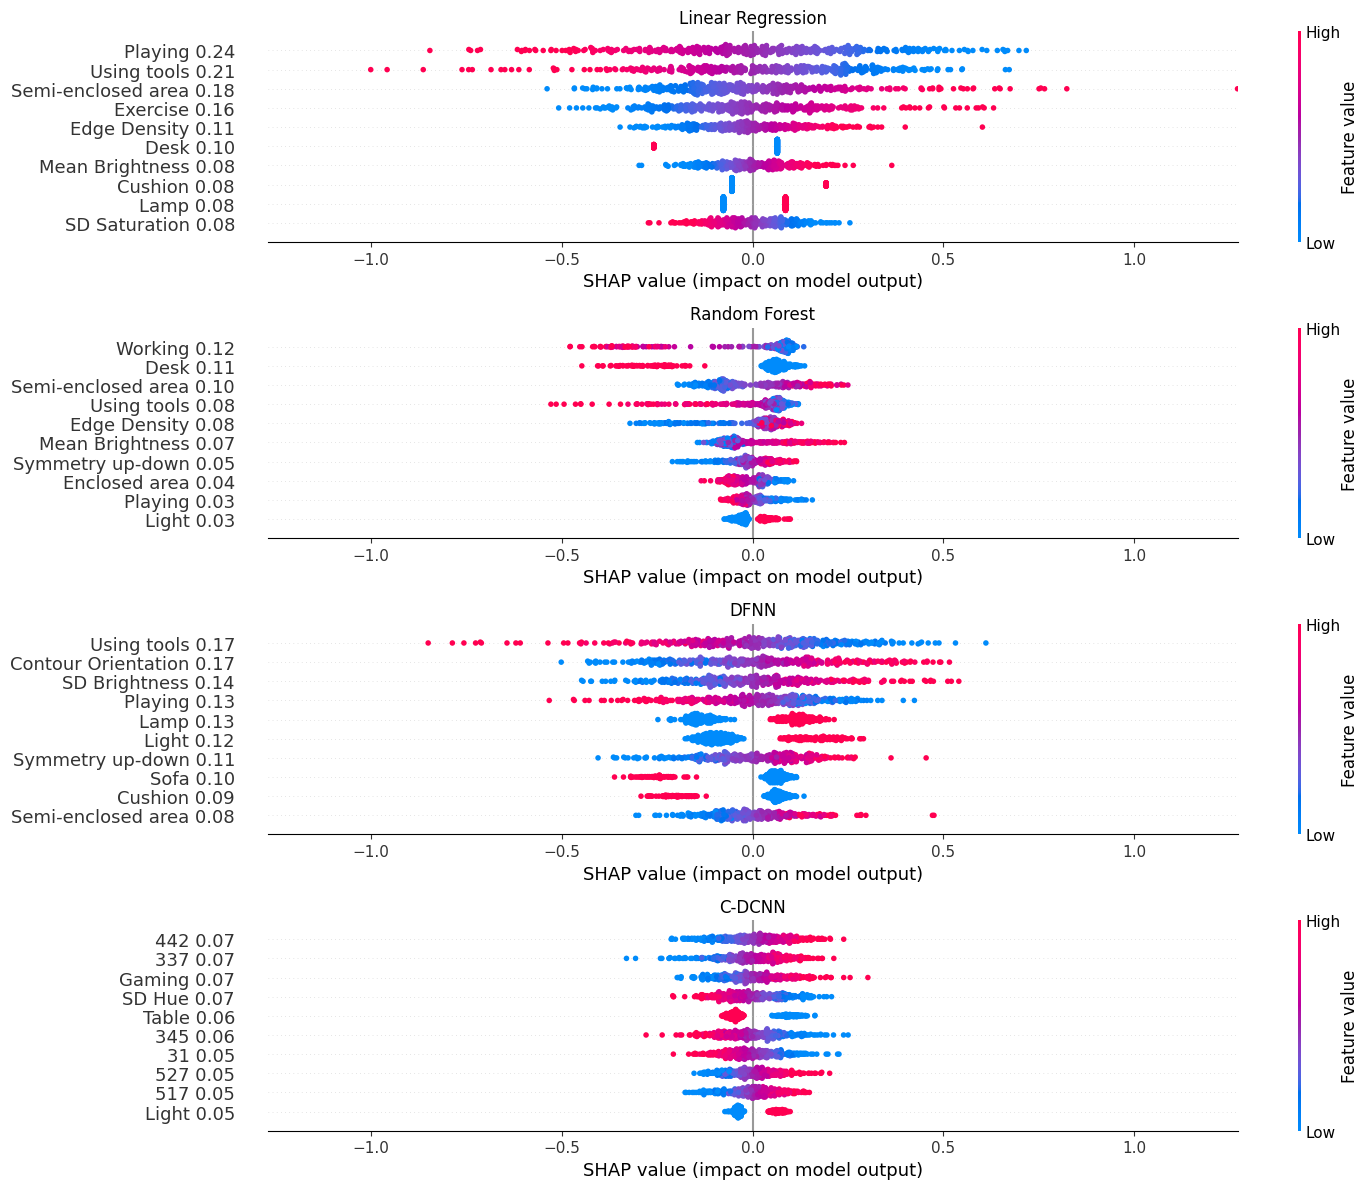

In [6]:
import importlib
import utils.shap_utils
importlib.reload(utils.shap_utils)
from utils.shap_utils import calculate_shap, shap_summary_plot_all_models

save_loc = "/home/fdeniz2/ML Paper/results/SHAP"
target = "valence"
split = list(repeated_k_fold.split(mean_data))
index_val = 0
train_idx, test_idx = split[index_val]

# Scale data based on train/test split
mean_data_scaled, scaler = scale_fold_data(mean_data, train_idx, test_idx, mean_data[mean_data.columns.difference(["image", "valence", "Unnamed: 0", "room_type", "approach", "tense", "energetic"])].columns)
combined_outputs_scaled, _ = scale_fold_data(combined_outputs, train_idx, test_idx, combined_outputs[combined_outputs.columns.difference(["image", "valence", "Unnamed: 0", "room_type", "approach", "tense", "energetic"])].columns)

X = mean_data_scaled[mean_data_scaled.columns.difference(["image", "valence", "Unnamed: 0", "room_type", "approach", "tense", "energetic"])]
X_dcnn = combined_outputs_scaled[combined_outputs_scaled.columns.difference(["image", "valence", "Unnamed: 0", "room_type", "approach", "tense", "energetic"])]
y = mean_data_scaled.valence

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
_,X_test_combined = X_dcnn.iloc[train_idx], X_dcnn.iloc[test_idx]

feature_names = X_train.columns

if os.path.exists(os.path.join(save_loc, f"shap_{target}_linear.npy")):
    shap_values_reg = np.load(os.path.join(save_loc, f"shap_{target}_linear.npy"))
else:
    linear_regression = LinearRegression()
    linear_regression.fit(X_train, y_train) 
    explainer = shap.LinearExplainer(linear_regression, X_train) 
    shap_values_reg = explainer(X_test).values.squeeze()
    np.save(os.path.join(save_loc, f"shap_{target}_linear.npy"),shap_values_reg)

if os.path.exists(os.path.join(save_loc, f"shap_{target}_forest.npy")):
    shap_values_forest = np.load(os.path.join(save_loc, f"shap_{target}_forest.npy"))
else:
    random_forest = RandomForestRegressor(n_jobs = -1, random_state=42, min_samples_leaf = 5, max_features = 0.5, min_impurity_decrease = 0)
    random_forest.fit(X_train, y_train)
    forest_explainer = shap.TreeExplainer(random_forest, X_train)
    shap_values_forest = forest_explainer(X_test).values.squeeze()
    np.save(os.path.join(save_loc, f"shap_{target}_forest.npy"),shap_values_forest)

if os.path.exists(os.path.join(save_loc, f"shap_{target}_dfnn.npy")):
    shap_values_dfnn = np.load(os.path.join(save_loc, f"shap_{target}_dfnn.npy"))
else:
    train_dataloader, test_dataloader, dataset = load_dataset(load_csv, False, mean_data_scaled, "valence", train_idx, test_idx, batch_size = 360)
    feature_names = list(X.columns)
    dfnn = prediction_head(number_of_visual_features, 0.2).to(device)
    dfnn.load_state_dict(torch.load(f'/home/fdeniz2/ML Paper/models/DFNN/{target}_{index_val}.pth'))
    shap_values_dfnn, test_inputs, dfnn_explainer = calculate_shap(dfnn, train_dataloader, test_dataloader, feature_names, device)
    shap_values_dfnn = shap_values_dfnn.values.squeeze()
    np.save(os.path.join(save_loc, f"shap_{target}_dfnn.npy"),shap_values_dfnn)

if os.path.exists(os.path.join(save_loc, f"shap_{target}_dcnn.npy")):
    shap_values_dcnn = np.load(os.path.join(save_loc, f"shap_{target}_dcnn.npy"))
    feature_names_dcnn_combined = list(combined_outputs.columns.difference(["image", "valence", "Unnamed: 0", "room_type", "approach", "tense", "energetic"]))
else:
    train_dataloader, test_dataloader, dataset = load_dataset(load_csv, False, combined_outputs_scaled, "valence", train_idx, test_idx, batch_size = 360)
    feature_names_dcnn_combined = list(combined_outputs.columns.difference(["image", "valence", "Unnamed: 0", "room_type", "approach", "tense", "energetic"]))
    dcnn = prediction_head(drop_out_rate=0.5, n_features = 768+number_of_visual_features)
    dcnn = dcnn.to(device)
    dcnn.load_state_dict(torch.load(f'/home/fdeniz2/ML Paper/models/C-DCNN/{target}_{index_val}.pth'))
    shap_values_dcnn, test_inputs_dcnn, dcnn_explainer = calculate_shap(dcnn, train_dataloader, test_dataloader, feature_names_dcnn_combined, device)
    shap_values_dcnn = shap_values_dcnn.values.squeeze()
    np.save(os.path.join(save_loc, f"shap_{target}_dcnn.npy"),shap_values_dcnn)

shap_summary_plot_all_models(shap_values_reg, X_test, 
                             shap_values_forest, X_test,
                             shap_values_dfnn, X_test,
                             shap_values_dcnn, X_test_combined,
                             _, feature_names_dcnn_combined,
                             True, f"/home/fdeniz2/ML Paper/figures/{target}_importance.svg")

In [35]:
plot_shap_all(shap_values_reg, X_test, feature_names, "LR",
              save_path=f"/home/fdeniz2/ML Paper/figures/{target}_lr_all.png")

plot_shap_all(shap_values_forest, X_test, feature_names, "RF",
              save_path=f"/home/fdeniz2/ML Paper/figures/{target}_rf_all.png")

plot_shap_all(shap_values_dfnn, X_test, feature_names, "DFNN",
              save_path=f"/home/fdeniz2/ML Paper/figures/{target}_dfnn_all.png")

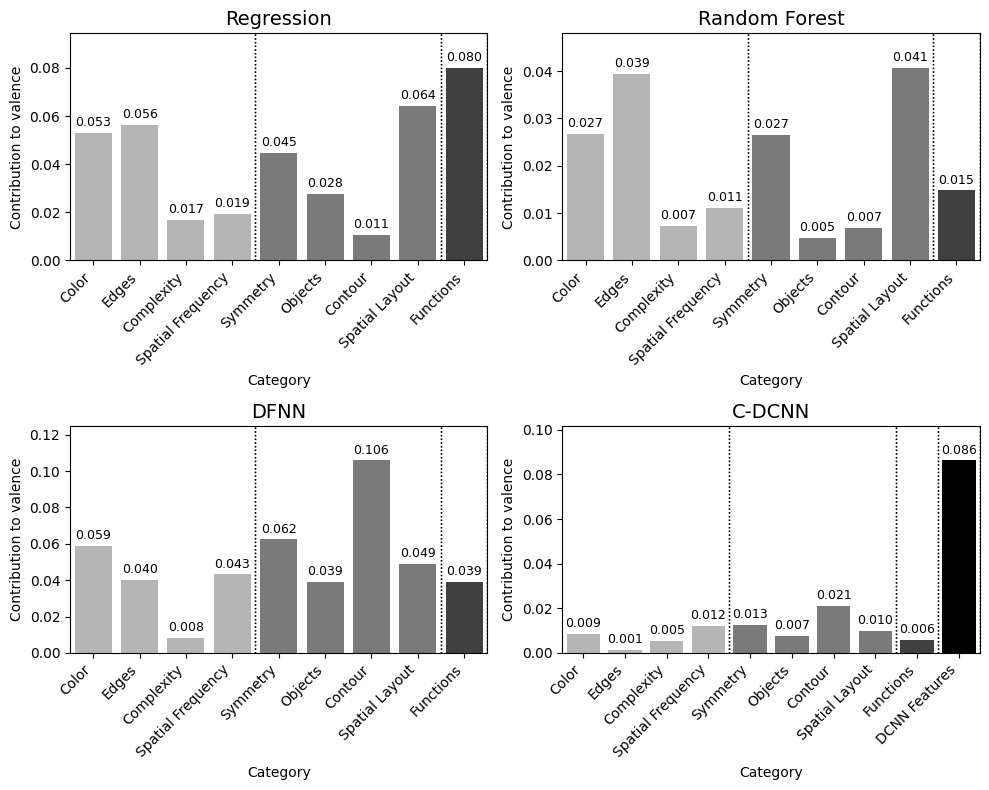

In [10]:
from utils.shap_utils import find_contribution, plot_contributions
importlib.reload(utils.shap_utils)

from utils.shap_utils import find_contribution, plot_contributions

contributions_reg, contributions_reg_group = find_contribution(shap_values_reg, feature_names)
contributions_forest, contributions_forest_group = find_contribution(shap_values_forest, feature_names)
contributions_dfnn, contributions_dfnn_group = find_contribution(shap_values_dfnn, feature_names)
contributions_dcnn, contributions_dcnn_group = find_contribution(shap_values_dcnn, feature_names, True)

fig = plt.figure(figsize=(10, 8))
gs = GridSpec(2, 2, figure=fig)

ax1 = fig.add_subplot(gs[0, 0])
ax1.set_title("Regression", fontsize=14)
plot_contributions(ax1, contributions_reg, contributions_reg_group)
ax1.set_xticklabels(["Color", "Edges", "Complexity", "Spatial Frequency", "Symmetry", "Objects", "Contour", "Spatial Layout", "Functions"], rotation=45, ha="right")
ax1.set_ylabel('Contribution to valence')

ax2 = fig.add_subplot(gs[0, 1])
ax2.set_title("Random Forest", fontsize=14)
plot_contributions(ax2, contributions_forest, contributions_forest_group)
ax2.set_xticklabels(["Color", "Edges", "Complexity", "Spatial Frequency", "Symmetry", "Objects", "Contour", "Spatial Layout", "Functions"], rotation=45, ha="right")
ax2.set_ylabel('Contribution to valence')

ax3 = fig.add_subplot(gs[1, 0])
ax3.set_title("DFNN", fontsize=14)
plot_contributions(ax3, contributions_dfnn, contributions_dfnn_group)
ax3.set_xticklabels(["Color", "Edges", "Complexity", "Spatial Frequency", "Symmetry", "Objects", "Contour", "Spatial Layout", "Functions"], rotation=45, ha="right")
ax3.set_ylabel('Contribution to valence')

ax4 = fig.add_subplot(gs[1, 1])
ax4.set_title("C-DCNN", fontsize=14)
plot_contributions(ax4, contributions_dcnn, contributions_dcnn_group, extra_label="DCNN Features")
ax4.set_xticklabels(["Color", "Edges", "Complexity", "Spatial Frequency", "Symmetry", "Objects", "Contour", "Spatial Layout", "Functions", "DCNN Features"], rotation=45, ha="right")
ax4.set_ylabel('Contribution to valence')

plt.tight_layout()
plt.savefig("/home/fdeniz2/ML Paper/figures/valence_overall_importance.svg", format="svg")
plt.show()

In [9]:
expected_value = forest_explainer.expected_value
random_set = np.random.randint(0, 360, size=50)

fig, axes = plt.subplots(3, 1, figsize=(25, 20))
plt.sca(axes[0])  # Set current axis
shap.decision_plot(expected_value, shap_values_reg[random_set,:], X_test.columns,feature_display_range=slice(None, None, -1),show = False)
axes[0].set_title("Linear Regression")

plt.sca(axes[1])  # Set current axis
shap.decision_plot(expected_value, shap_values_forest[random_set,:], X_test.columns,feature_display_range=slice(None, None, -1),show = False)
axes[1].set_title("Random Forest")

plt.sca(axes[2])  # Set current axis
shap.decision_plot(expected_value, shap_values_dfnn[random_set,:], X_test.columns,feature_display_range=slice(None, None, -1),show = False)
axes[2].set_title("DFNN")

axes[0].tick_params(axis='y', labelsize=8)
axes[1].tick_params(axis='y', labelsize=8)
axes[2].tick_params(axis='y', labelsize=8)

plt.tight_layout()

plt.savefig("/home/fdeniz2/ML Paper/figures/valence_decision_plot.svg", format = "svg")
plt.close()

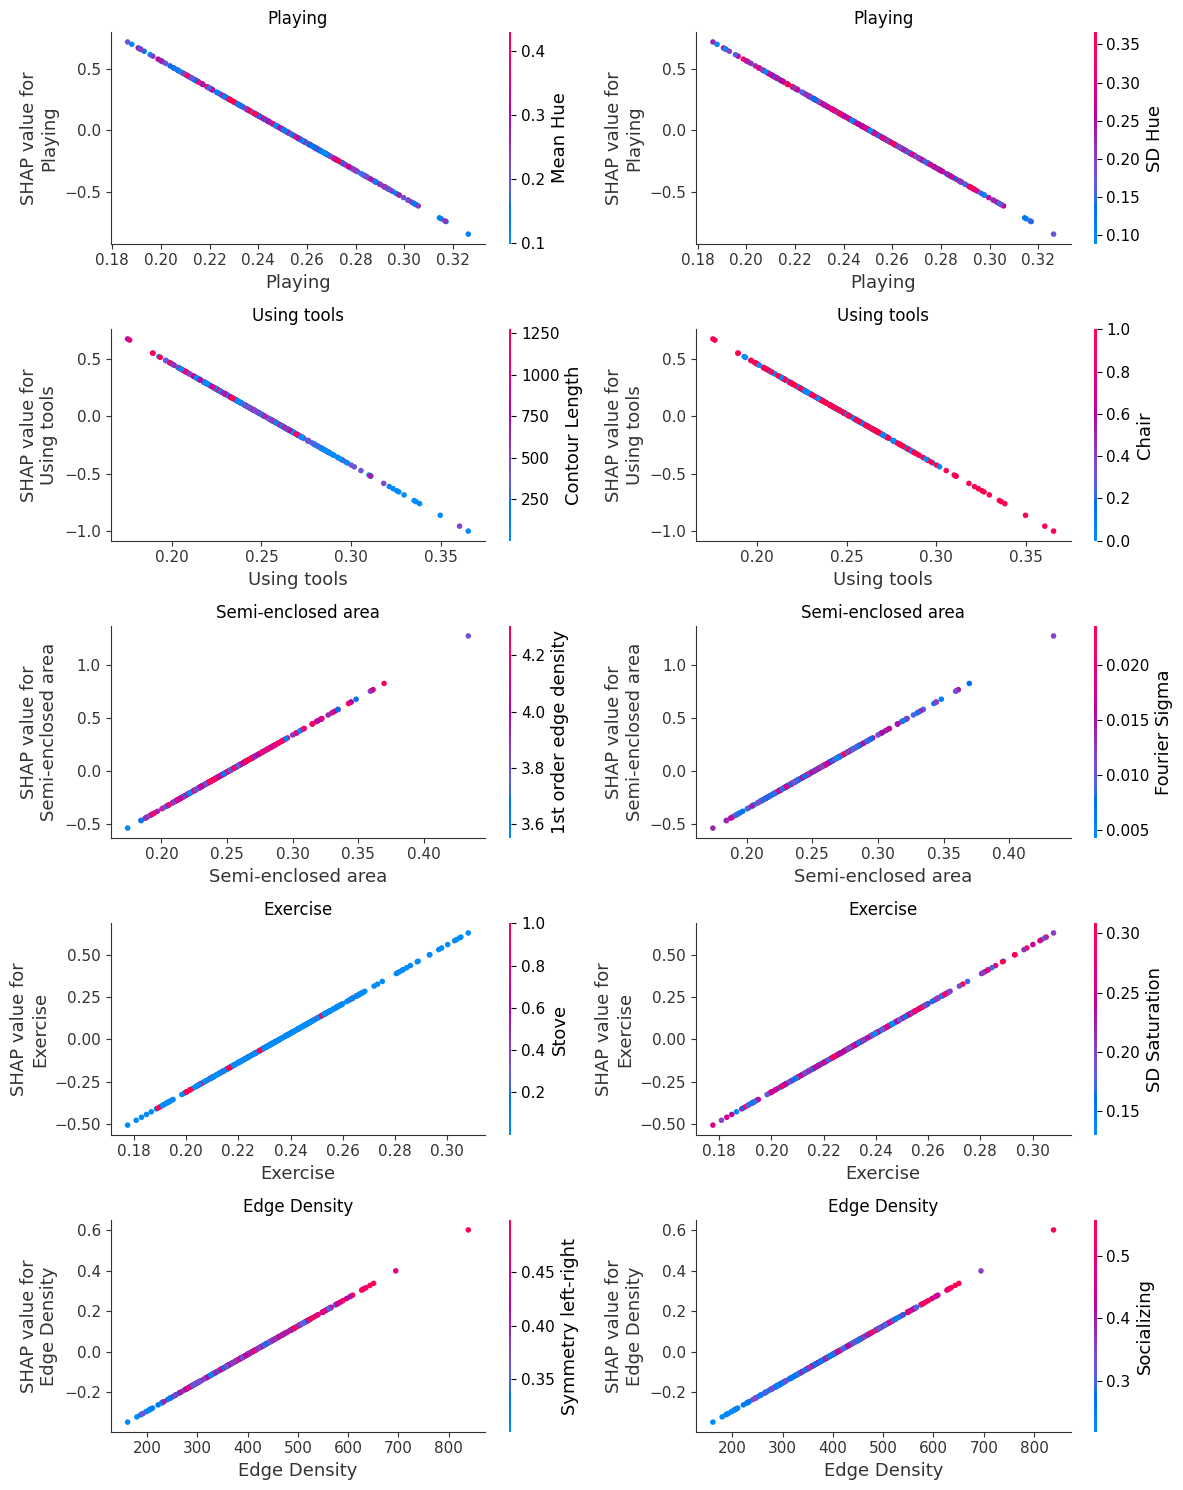

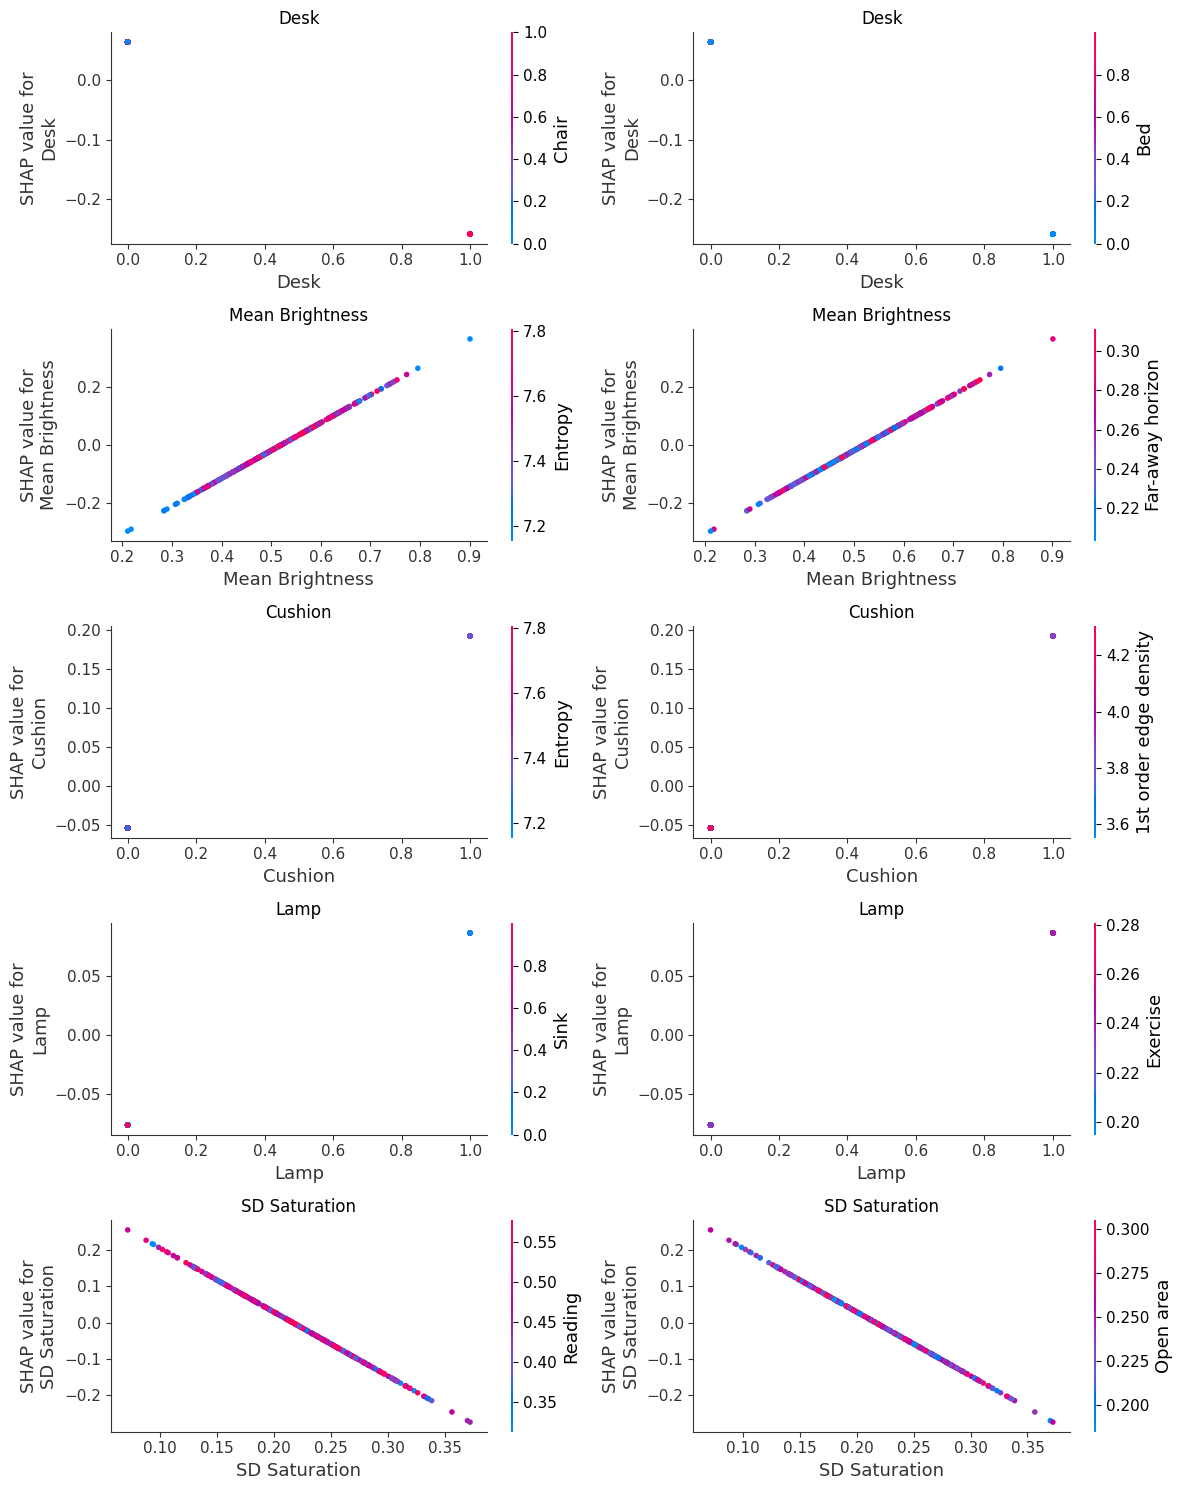

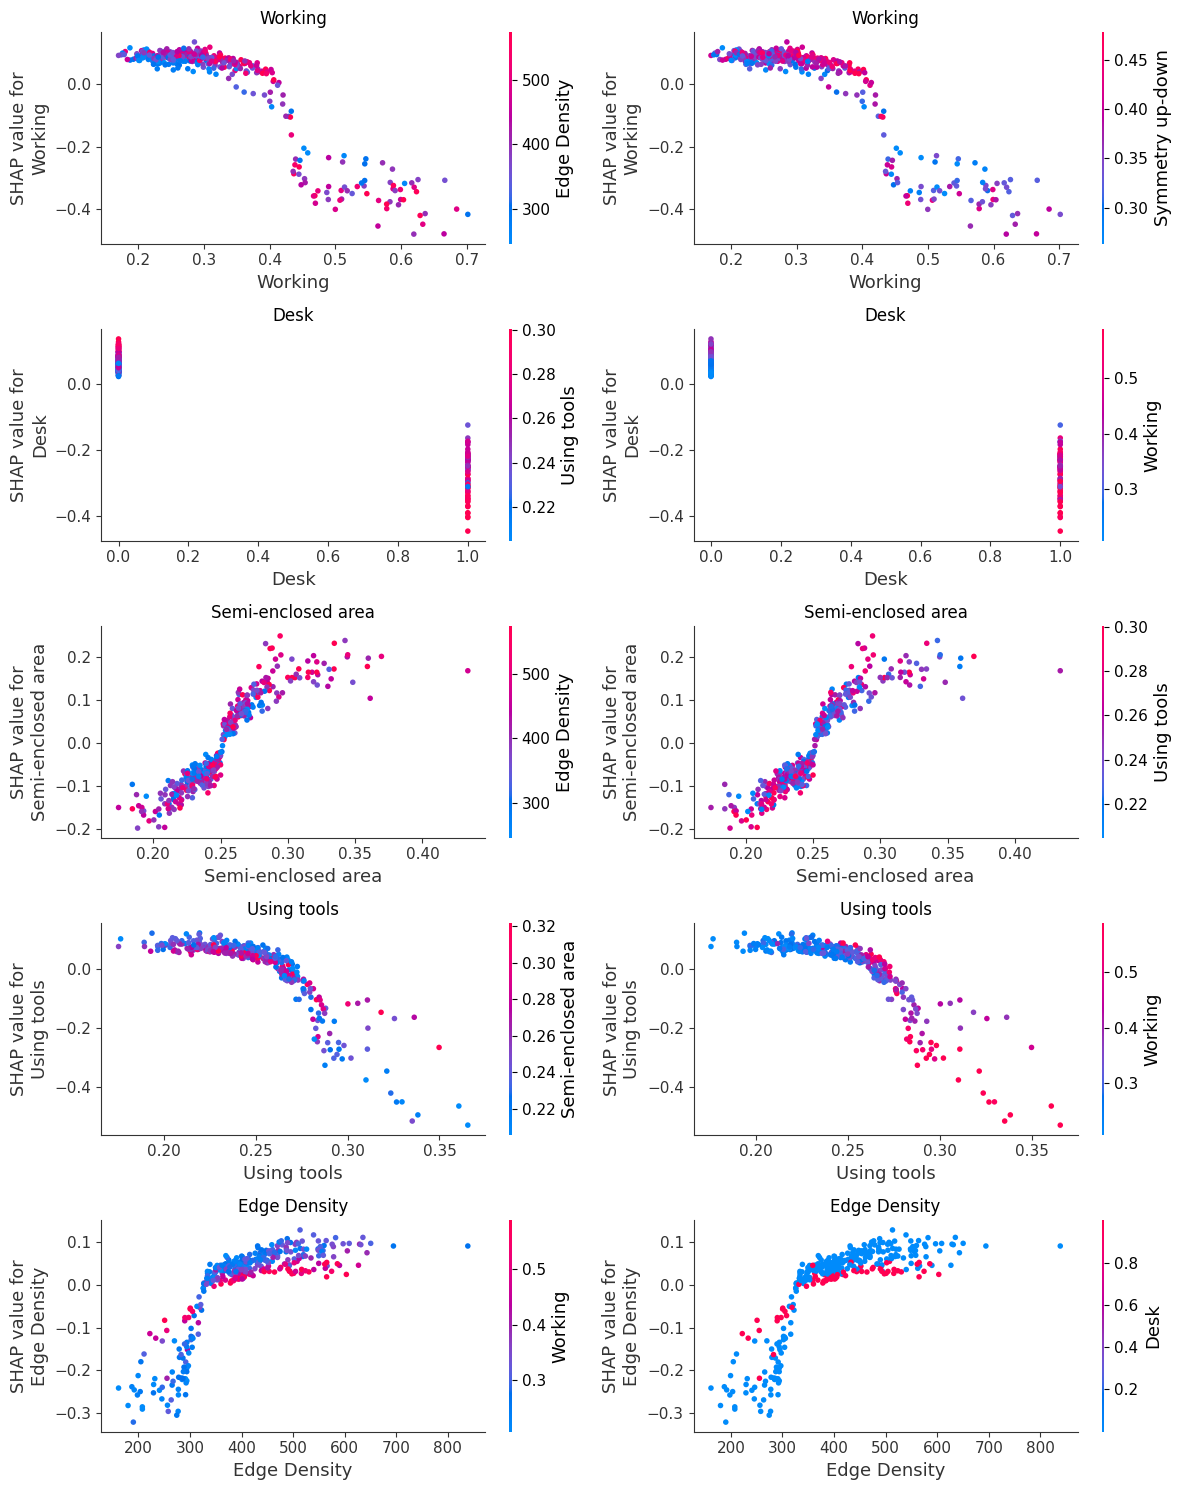

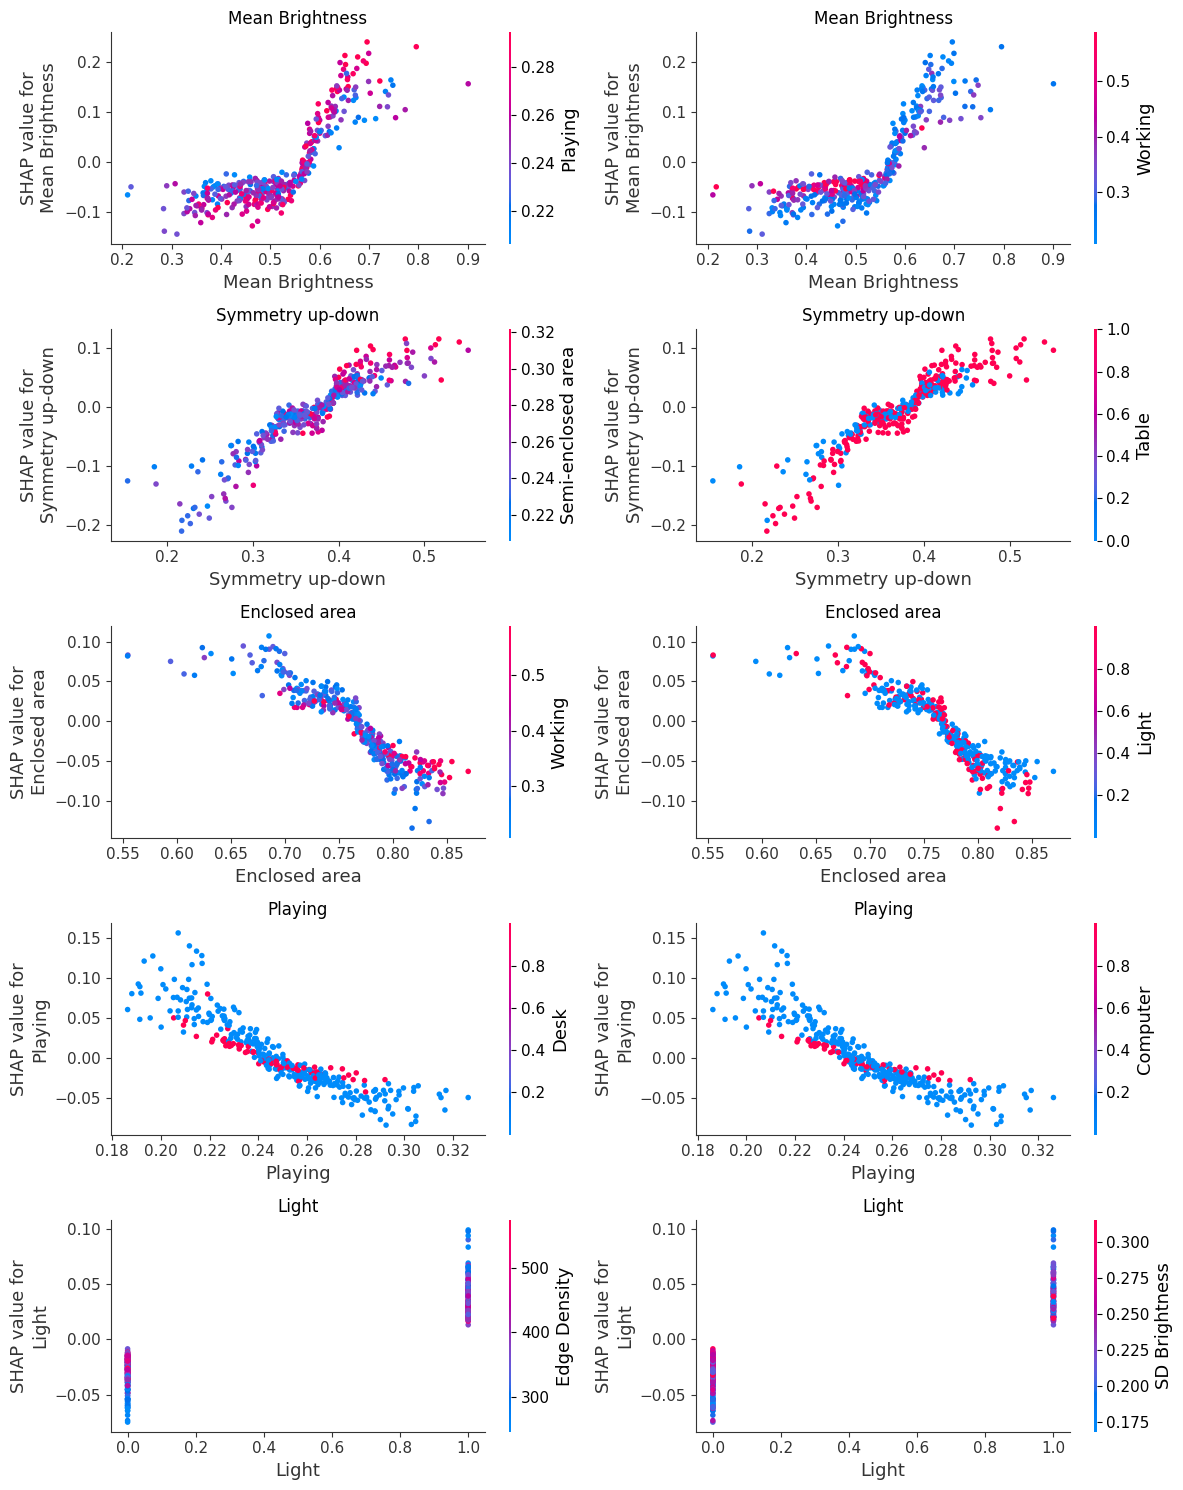

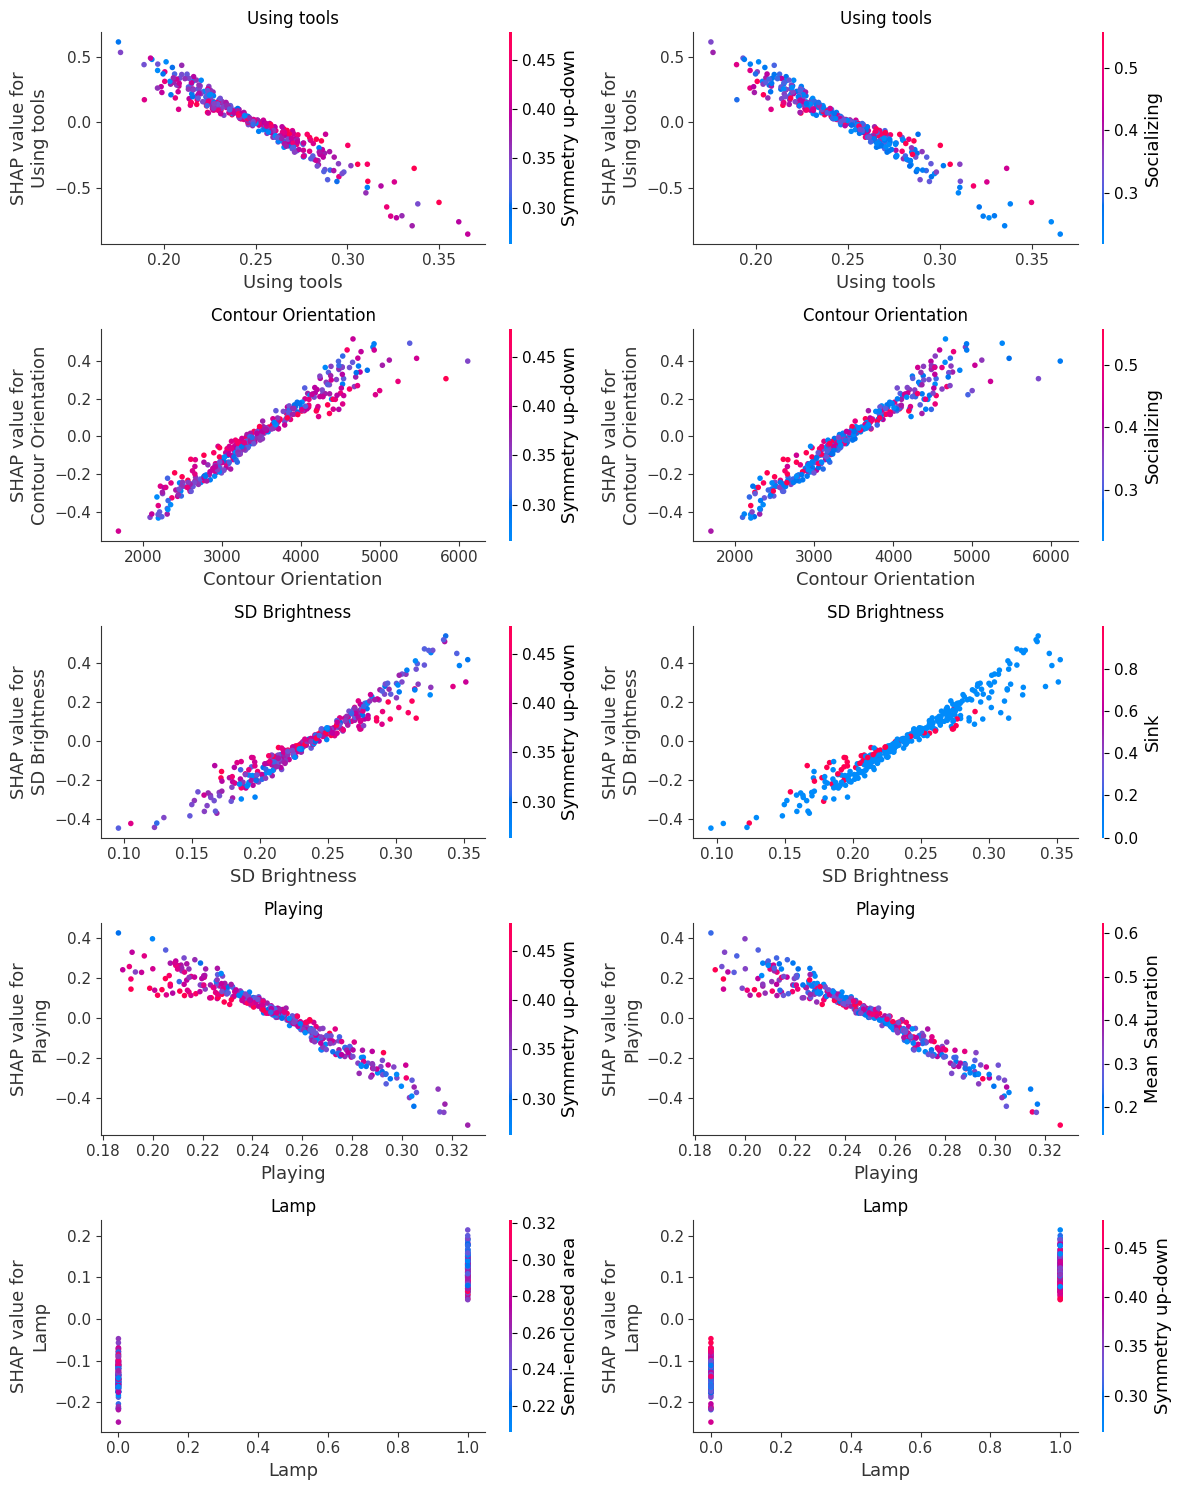

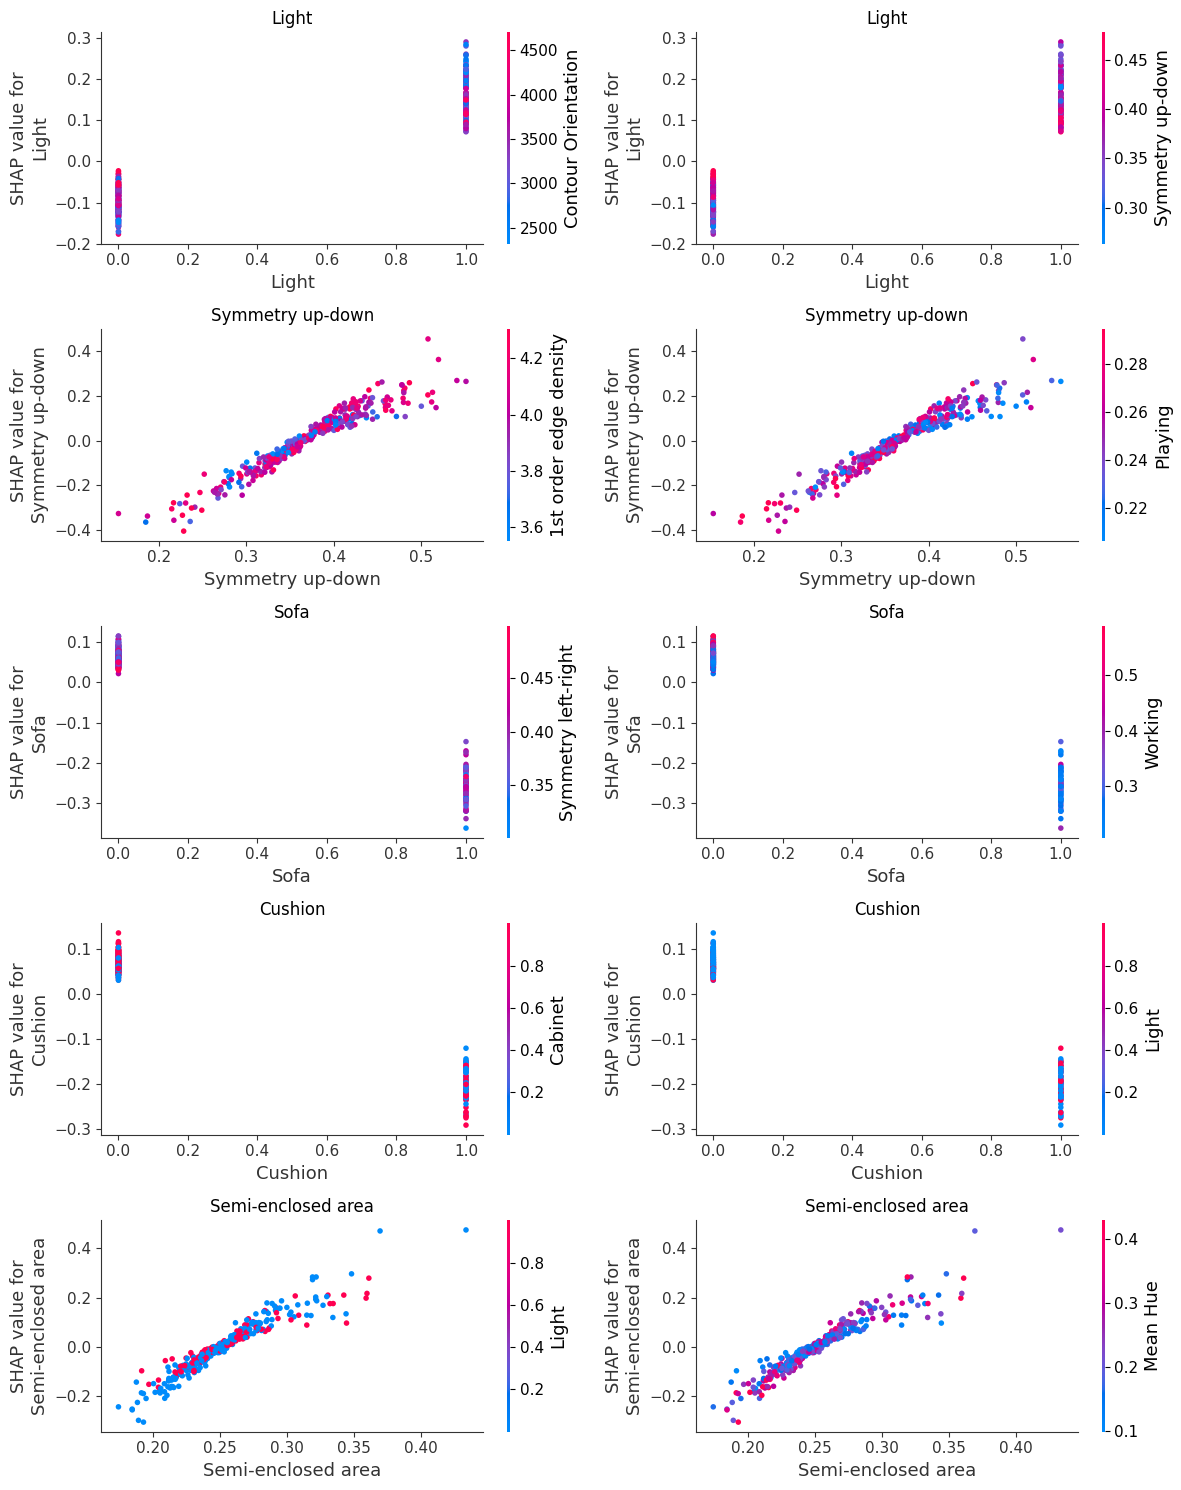

In [8]:
from utils.shap_utils import dependence_with_interaction
import math 
import os
def get_top_shap_names(X_test, shap_values,n):

    return list(X_test.columns[np.argsort(np.abs(shap_values).mean(0))[::-1]][:n])

def dependence_with_interaction(X_test, shap_values, save, save_loc,
                                n_features=10, per_fig=5, n_interactions=2,
                                fig_width=12, row_height=3):
    top_shap = list(get_top_shap_names(X_test, shap_values, n_features))
    base, ext = os.path.splitext(save_loc)
    n_figs = math.ceil(len(top_shap) / per_fig)

    for f in range(n_figs):
        chunk = top_shap[f * per_fig:(f + 1) * per_fig]
        fig, axes = plt.subplots(len(chunk), n_interactions,
                                 figsize=(fig_width, row_height * len(chunk)),
                                 squeeze=False)

        for r, feat in enumerate(chunk):
            feat_idx = X_test.columns.get_loc(feat)
            inter = shap.utils.approximate_interactions(feat_idx, shap_values, X_test)[:n_interactions]
            for c, inter_idx in enumerate(inter):
                ax = axes[r, c]
                shap.dependence_plot(feat_idx, shap_values, X_test,
                                     interaction_index=X_test.columns[inter_idx],
                                     ax=ax, show=False)
                ax.set_title(feat)

        fig.tight_layout()
        if save:
            fig.savefig(f"{base}_part{f + 1}{ext}", format="svg", bbox_inches="tight")
        plt.show()
        plt.close(fig)



X_test_inverse = pd.DataFrame(scaler.inverse_transform(X_test), columns=X_test.columns)
fig_dir = "/home/fdeniz2/ML Paper/figures/"

dependence_with_interaction(X_test_inverse, shap_values_reg,    True, fig_dir + "valence_dependence_plot_regression.svg")
dependence_with_interaction(X_test_inverse, shap_values_forest, True, fig_dir + "valence_dependence_plot_forest.svg")
dependence_with_interaction(X_test_inverse, shap_values_dfnn,   True, fig_dir + "valence_dependence_plot_dfnn.svg")

### Combined Results

In [12]:
dcnn = pd.read_csv("/home/fdeniz2/models/results/model_performance_valence_dcnn.csv")
cdcnn = pd.read_csv("/home/fdeniz2/models/results/model_performance_valence_c_dcnn.csv")
dfnn = pd.read_csv("/home/fdeniz2/models/results/model_performance_valence_dfnn.csv")
model_performance_approach_lr = pd.read_csv("/home/fdeniz2/models/results/model_performance_valence_lr.csv")
model_performance_approach_rf = pd.read_csv("/home/fdeniz2/models/results/model_performance_valence_rf.csv")
all_results = pd.concat([model_performance_approach_lr, model_performance_approach_rf, dfnn, dcnn,cdcnn])
all_results.to_csv("/home/fdeniz2/models/results//all_results_valence.csv")

# Tense Arousal

### Random Forest

In [22]:
from sklearn.pipeline import Pipeline

X = mean_data[mean_data.columns.difference(["image", "valence", "Unnamed: 0", "room_type", "approach", "tense", "energetic"])]
y = mean_data.tense

param_distributions = {
    'forest__max_features': ['sqrt', 'log2', None, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9],
    'forest__min_samples_leaf': [1, 2, 3, 5, 10],
    'forest__min_impurity_decrease': [0.0, 0.01, 0.02, 0.05]
}

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("forest", RandomForestRegressor(n_jobs = -1, random_state=42))
])

search = RandomizedSearchCV(estimator=pipeline,param_distributions=param_distributions,  scoring='neg_mean_absolute_error', 
    n_jobs=-1,cv=repeated_k_fold,verbose=1,random_state = 42, n_iter = 10)

search.fit(X, y)

random_forest_tense = search.best_estimator_
model_performance_tense_rf, shap_valence_rf, feature_names = fit_models_cross_validation(X, y, random_forest_tense, repeated_k_fold, shap.TreeExplainer, False, False)
model_performance_tense_rf = to_dataframe_(model_performance_tense_rf, "RF")
print(f"Mean model performance {model_performance_tense_rf['Rsquared'].mean()}")
model_performance_tense_rf.to_csv("./results/model_performance_tense_rf.csv")
print("Results are saved")


Fitting 30 folds for each of 10 candidates, totalling 300 fits
Mean model performance 0.6081685219166982
Results are saved


### Linear

In [23]:
linear_regression = Pipeline([
    ("scaler", StandardScaler()),
    ("regression", LinearRegression())
])
model_performance_tense_lr, shap_tense_lr, feature_names = fit_models_cross_validation(X, y, linear_regression, repeated_k_fold, shap.LinearExplainer, True, False)
model_performance_tense_lr = to_dataframe_(model_performance_tense_lr, "LR")
model_performance_tense_lr.to_csv("/home/fdeniz2/models/results/model_performance_tense_lr.csv")
print(f"Mean model performance {model_performance_tense_lr['Rsquared'].mean()}")
print("Results are saved")

Mean model performance 0.6074341375842718
Results are saved


### Shap

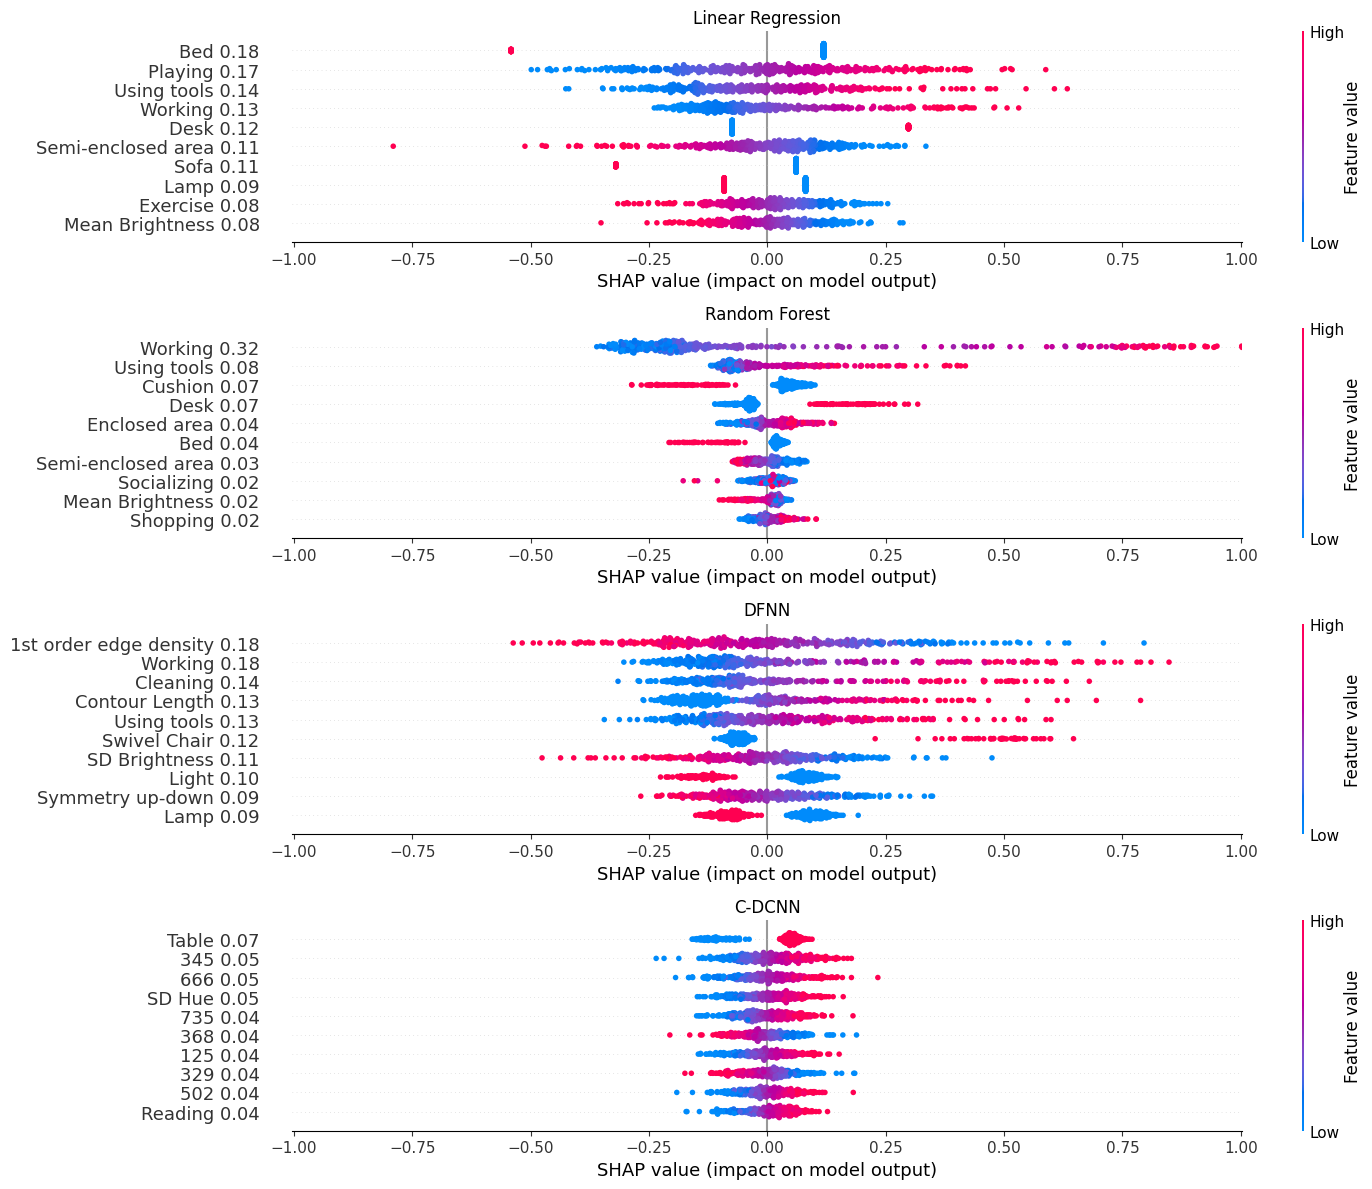

In [10]:
import importlib
import utils.shap_utils
importlib.reload(utils.shap_utils)
from utils.shap_utils import calculate_shap, shap_summary_plot_all_models

save_loc = "/home/fdeniz2/ML Paper/results/SHAP"
target = "tense"
split = list(repeated_k_fold.split(mean_data))
index_val = 0 
train_idx, test_idx = split[index_val]

# Scale data based on train/test split
mean_data_scaled, scaler = scale_fold_data(mean_data, train_idx, test_idx, mean_data[mean_data.columns.difference(["image", "valence", "Unnamed: 0", "room_type", "approach", "tense", "energetic"])].columns)
combined_outputs_scaled, _ = scale_fold_data(combined_outputs, train_idx, test_idx, combined_outputs[combined_outputs.columns.difference(["image", "valence", "Unnamed: 0", "room_type", "approach", "tense", "energetic"])].columns)

X = mean_data_scaled[mean_data_scaled.columns.difference(["image", "valence", "Unnamed: 0", "room_type", "approach", "tense", "energetic"])]
X_dcnn = combined_outputs_scaled[combined_outputs_scaled.columns.difference(["image", "valence", "Unnamed: 0", "room_type", "approach", "tense", "energetic"])]
y = mean_data_scaled[target]

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
_,X_test_combined = X_dcnn.iloc[train_idx], X_dcnn.iloc[test_idx]

feature_names = X_train.columns

if os.path.exists(os.path.join(save_loc, f"shap_{target}_linear.npy")):
    shap_values_reg = np.load(os.path.join(save_loc, f"shap_{target}_linear.npy"))
else:
    linear_regression = LinearRegression()
    linear_regression.fit(X_train, y_train) 
    explainer = shap.LinearExplainer(linear_regression, X_train) 
    shap_values_reg = explainer(X_test).values.squeeze()
    np.save(os.path.join(save_loc, f"shap_{target}_linear.npy"),shap_values_reg)

if os.path.exists(os.path.join(save_loc, f"shap_{target}_forest.npy")):
    shap_values_forest = np.load(os.path.join(save_loc, f"shap_{target}_forest.npy"))
else:
    random_forest = RandomForestRegressor(n_jobs = -1, random_state=42, min_samples_leaf = 5, max_features = 0.5, min_impurity_decrease = 0)
    random_forest.fit(X_train, y_train)
    forest_explainer = shap.TreeExplainer(random_forest, X_train)
    shap_values_forest = forest_explainer(X_test).values.squeeze()
    np.save(os.path.join(save_loc, f"shap_{target}_forest.npy"),shap_values_forest)

if os.path.exists(os.path.join(save_loc, f"shap_{target}_dfnn.npy")):
    shap_values_dfnn = np.load(os.path.join(save_loc, f"shap_{target}_dfnn.npy"))
else:
    train_dataloader, test_dataloader, dataset = load_dataset(load_csv, False, mean_data_scaled, "valence", train_idx, test_idx, batch_size = 360)
    feature_names = list(X.columns)
    dfnn = prediction_head(number_of_visual_features, 0.2).to(device)
    dfnn.load_state_dict(torch.load(f'/home/fdeniz2/ML Paper/models/DFNN/{target}_{index_val}.pth'))
    shap_values_dfnn, test_inputs, dfnn_explainer = calculate_shap(dfnn, train_dataloader, test_dataloader, feature_names, device)
    shap_values_dfnn = shap_values_dfnn.values.squeeze()
    np.save(os.path.join(save_loc, f"shap_{target}_dfnn.npy"),shap_values_dfnn)

if os.path.exists(os.path.join(save_loc, f"shap_{target}_dcnn.npy")):
    shap_values_dcnn = np.load(os.path.join(save_loc, f"shap_{target}_dcnn.npy"))
    feature_names_dcnn_combined = list(combined_outputs.columns.difference(["image", "valence", "Unnamed: 0", "room_type", "approach", "tense", "energetic"]))
else:
    train_dataloader, test_dataloader, dataset = load_dataset(load_csv, False, combined_outputs_scaled, "valence", train_idx, test_idx, batch_size = 360)
    feature_names_dcnn_combined = list(combined_outputs.columns.difference(["image", "valence", "Unnamed: 0", "room_type", "approach", "tense", "energetic"]))
    dcnn = prediction_head(drop_out_rate=0.5, n_features = 768+number_of_visual_features)
    dcnn = dcnn.to(device)
    dcnn.load_state_dict(torch.load(f'/home/fdeniz2/ML Paper/models/C-DCNN/{target}_{index_val}.pth'))
    shap_values_dcnn, test_inputs_dcnn, dcnn_explainer = calculate_shap(dcnn, train_dataloader, test_dataloader, feature_names_dcnn_combined, device)
    shap_values_dcnn = shap_values_dcnn.values.squeeze()
    np.save(os.path.join(save_loc, f"shap_{target}_dcnn.npy"),shap_values_dcnn)

shap_summary_plot_all_models(shap_values_reg, X_test, 
                             shap_values_forest, X_test,
                             shap_values_dfnn, X_test,
                             shap_values_dcnn, X_test_combined,
                             _, feature_names_dcnn_combined,
                             True, f"/home/fdeniz2/ML Paper/figures/{target}_importance.svg")

In [33]:
plot_shap_all(shap_values_reg, X_test, feature_names, "LR",
              save_path=f"/home/fdeniz2/ML Paper/figures/{target}_lr_all.png")

plot_shap_all(shap_values_forest, X_test, feature_names, "RF",
              save_path=f"/home/fdeniz2/ML Paper/figures/{target}_rf_all.png")

plot_shap_all(shap_values_dfnn, X_test, feature_names, "DFNN",
              save_path=f"/home/fdeniz2/ML Paper/figures/{target}_dfnn_all.png")

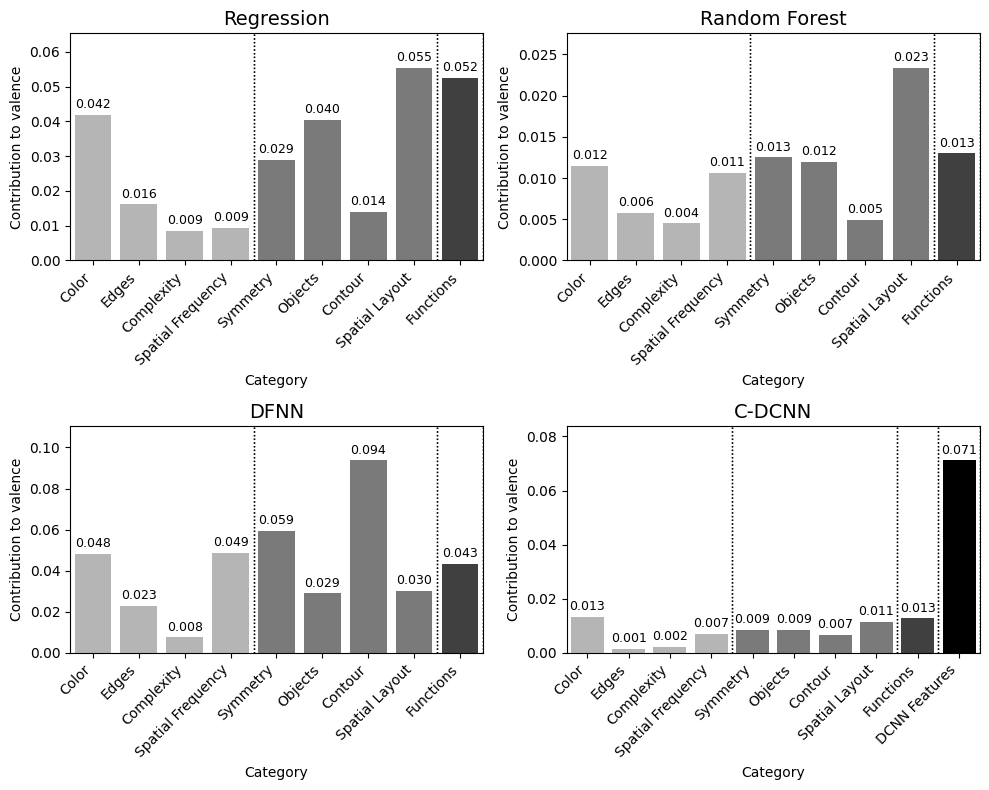

In [25]:
from utils.shap_utils import find_contribution, plot_contributions
importlib.reload(utils.shap_utils)

from utils.shap_utils import find_contribution, plot_contributions

contributions_reg, contributions_reg_group = find_contribution(shap_values_reg, feature_names)
contributions_forest, contributions_forest_group = find_contribution(shap_values_forest, feature_names)
contributions_dfnn, contributions_dfnn_group = find_contribution(shap_values_dfnn, feature_names)
contributions_dcnn, contributions_dcnn_group = find_contribution(shap_values_dcnn, feature_names, True)

fig = plt.figure(figsize=(10, 8))
gs = GridSpec(2, 2, figure=fig)

ax1 = fig.add_subplot(gs[0, 0])
ax1.set_title("Regression", fontsize=14)
plot_contributions(ax1, contributions_reg, contributions_reg_group)
ax1.set_xticklabels(["Color", "Edges", "Complexity", "Spatial Frequency", "Symmetry", "Objects", "Contour", "Spatial Layout", "Functions"], rotation=45, ha="right")
ax1.set_ylabel('Contribution to valence')

ax2 = fig.add_subplot(gs[0, 1])
ax2.set_title("Random Forest", fontsize=14)
plot_contributions(ax2, contributions_forest, contributions_forest_group)
ax2.set_xticklabels(["Color", "Edges", "Complexity", "Spatial Frequency", "Symmetry", "Objects", "Contour", "Spatial Layout", "Functions"], rotation=45, ha="right")
ax2.set_ylabel('Contribution to valence')

ax3 = fig.add_subplot(gs[1, 0])
ax3.set_title("DFNN", fontsize=14)
plot_contributions(ax3, contributions_dfnn, contributions_dfnn_group)
ax3.set_xticklabels(["Color", "Edges", "Complexity", "Spatial Frequency", "Symmetry", "Objects", "Contour", "Spatial Layout", "Functions"], rotation=45, ha="right")
ax3.set_ylabel('Contribution to valence')

ax4 = fig.add_subplot(gs[1, 1])
ax4.set_title("C-DCNN", fontsize=14)
plot_contributions(ax4, contributions_dcnn, contributions_dcnn_group, extra_label="DCNN Features")
ax4.set_xticklabels(["Color", "Edges", "Complexity", "Spatial Frequency", "Symmetry", "Objects", "Contour", "Spatial Layout", "Functions", "DCNN Features"], rotation=45, ha="right")
ax4.set_ylabel('Contribution to valence')

plt.tight_layout()
plt.savefig("/home/fdeniz2/ML Paper/figures/tense_overall_importance.svg", format="svg")
plt.show()

In [26]:
expected_value = forest_explainer.expected_value
random_set = np.random.randint(0, 360, size=50)

fig, axes = plt.subplots(3, 1, figsize=(25, 20))
plt.sca(axes[0])  # Set current axis
shap.decision_plot(expected_value, shap_values_reg[random_set,:], X_test.columns,feature_display_range=slice(None, None, -1),show = False)
axes[0].set_title("Linear Regression")

plt.sca(axes[1])  # Set current axis
shap.decision_plot(expected_value, shap_values_forest[random_set,:], X_test.columns,feature_display_range=slice(None, None, -1),show = False)
axes[1].set_title("Random Forest")

plt.sca(axes[2])  # Set current axis
shap.decision_plot(expected_value, shap_values_dfnn[random_set,:], X_test.columns,feature_display_range=slice(None, None, -1),show = False)
axes[2].set_title("DFNN")

axes[0].tick_params(axis='y', labelsize=8)
axes[1].tick_params(axis='y', labelsize=8)
axes[2].tick_params(axis='y', labelsize=8)

plt.tight_layout()

plt.savefig("/home/fdeniz2/ML Paper/figures/tense_decision_plot.svg", format = "svg")
plt.close()

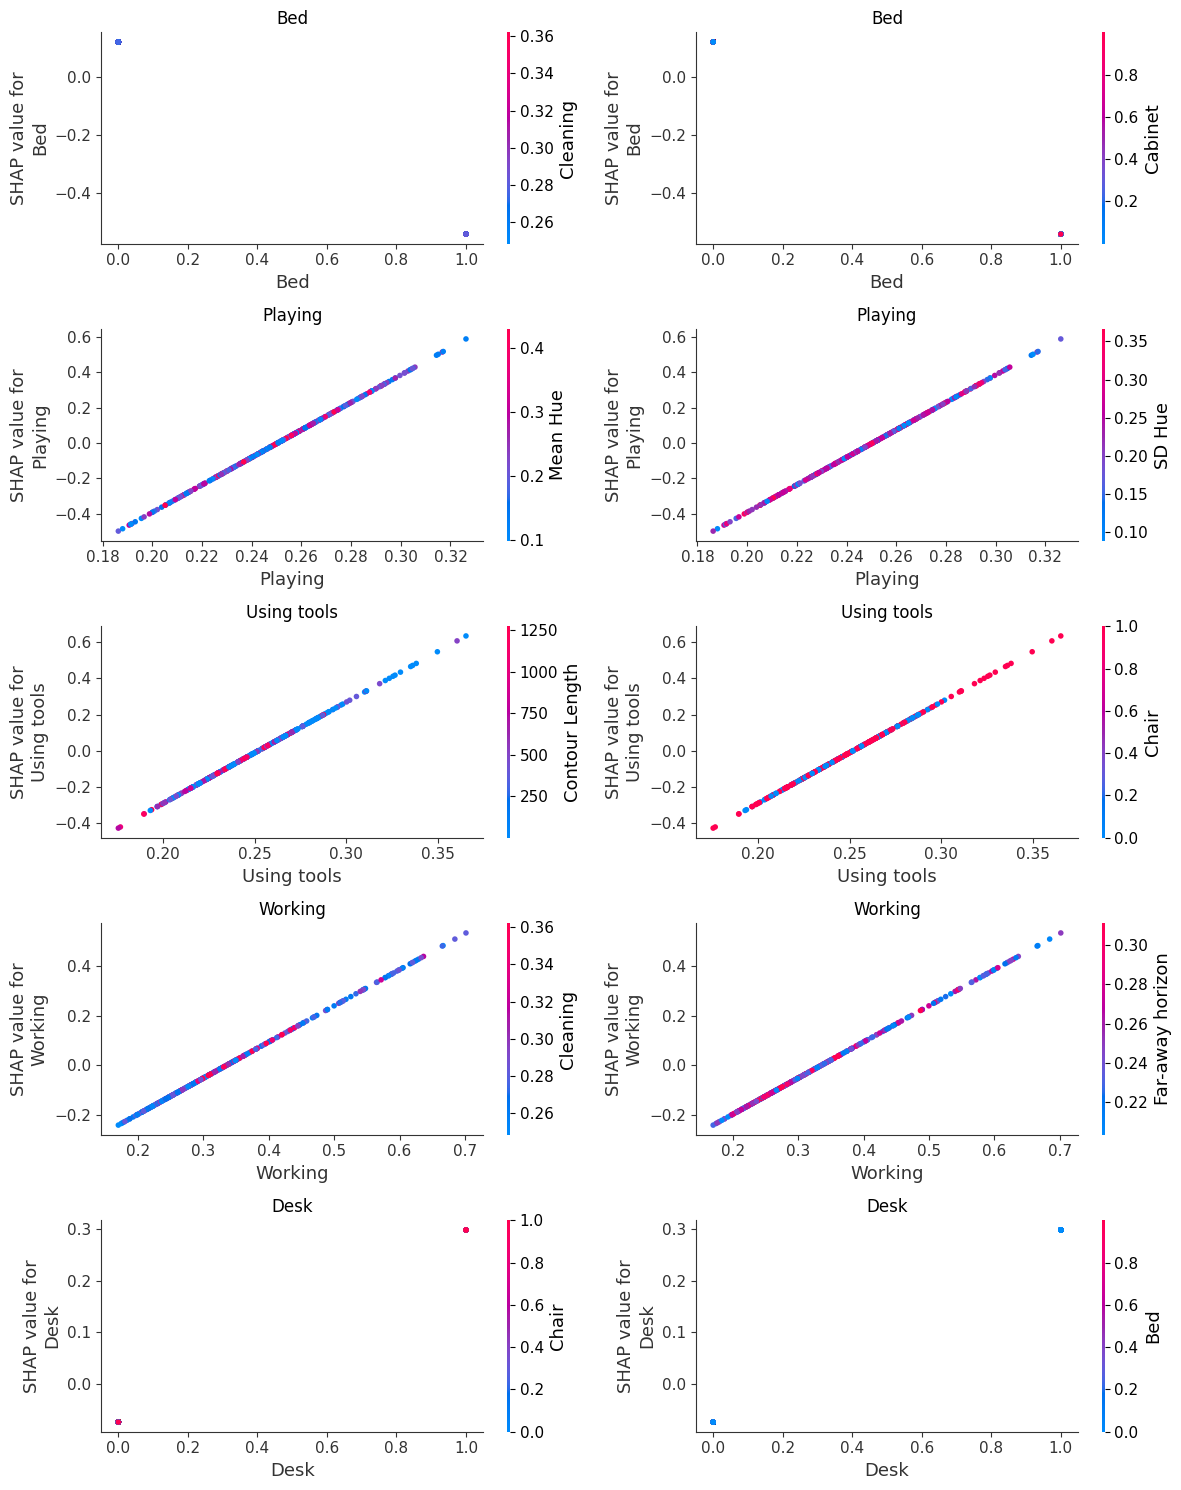

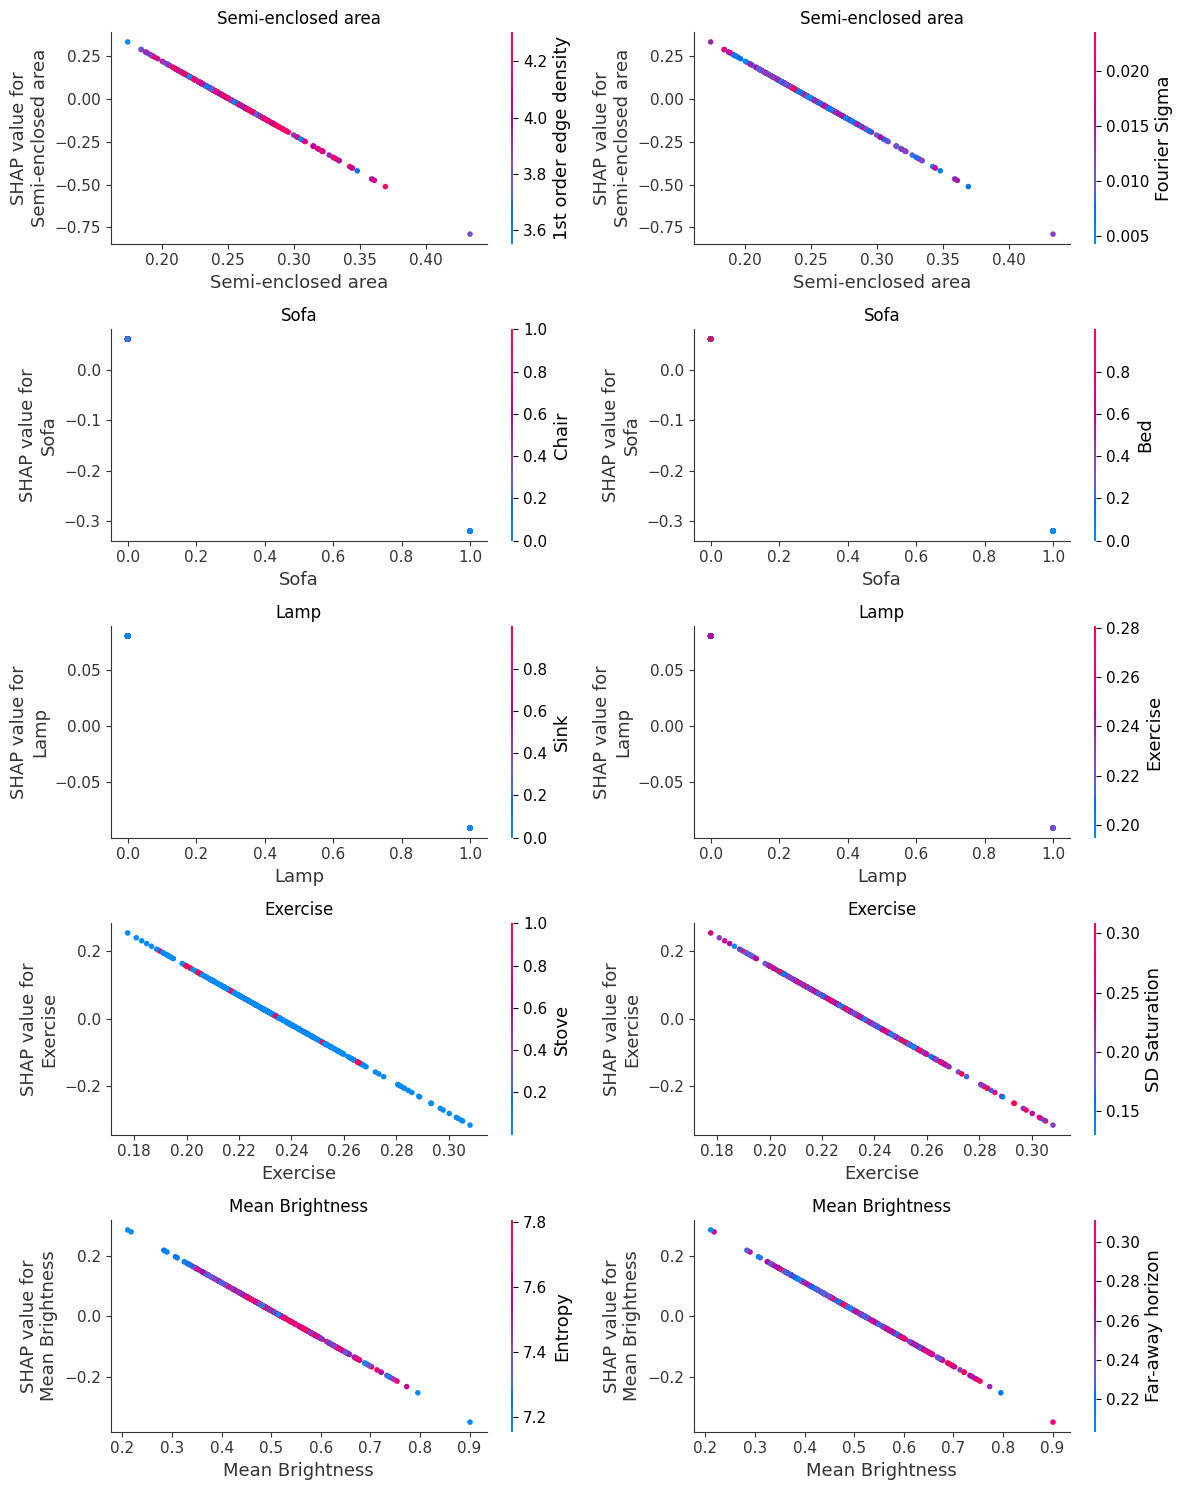

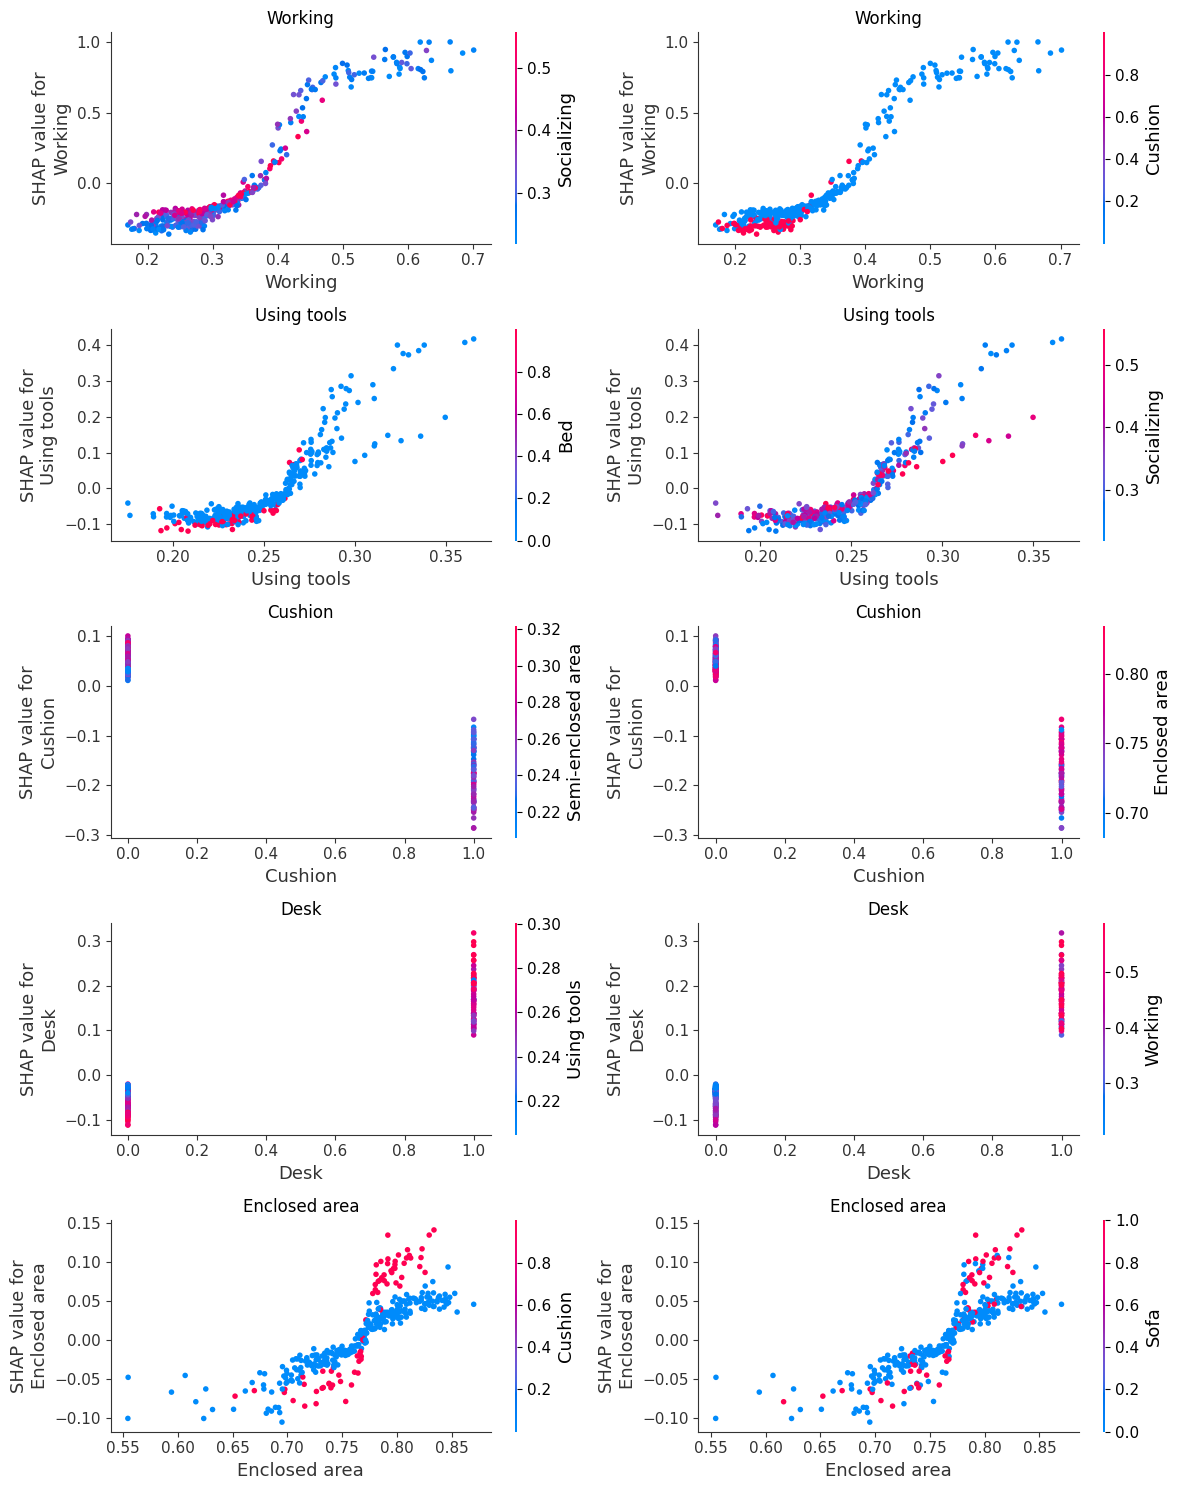

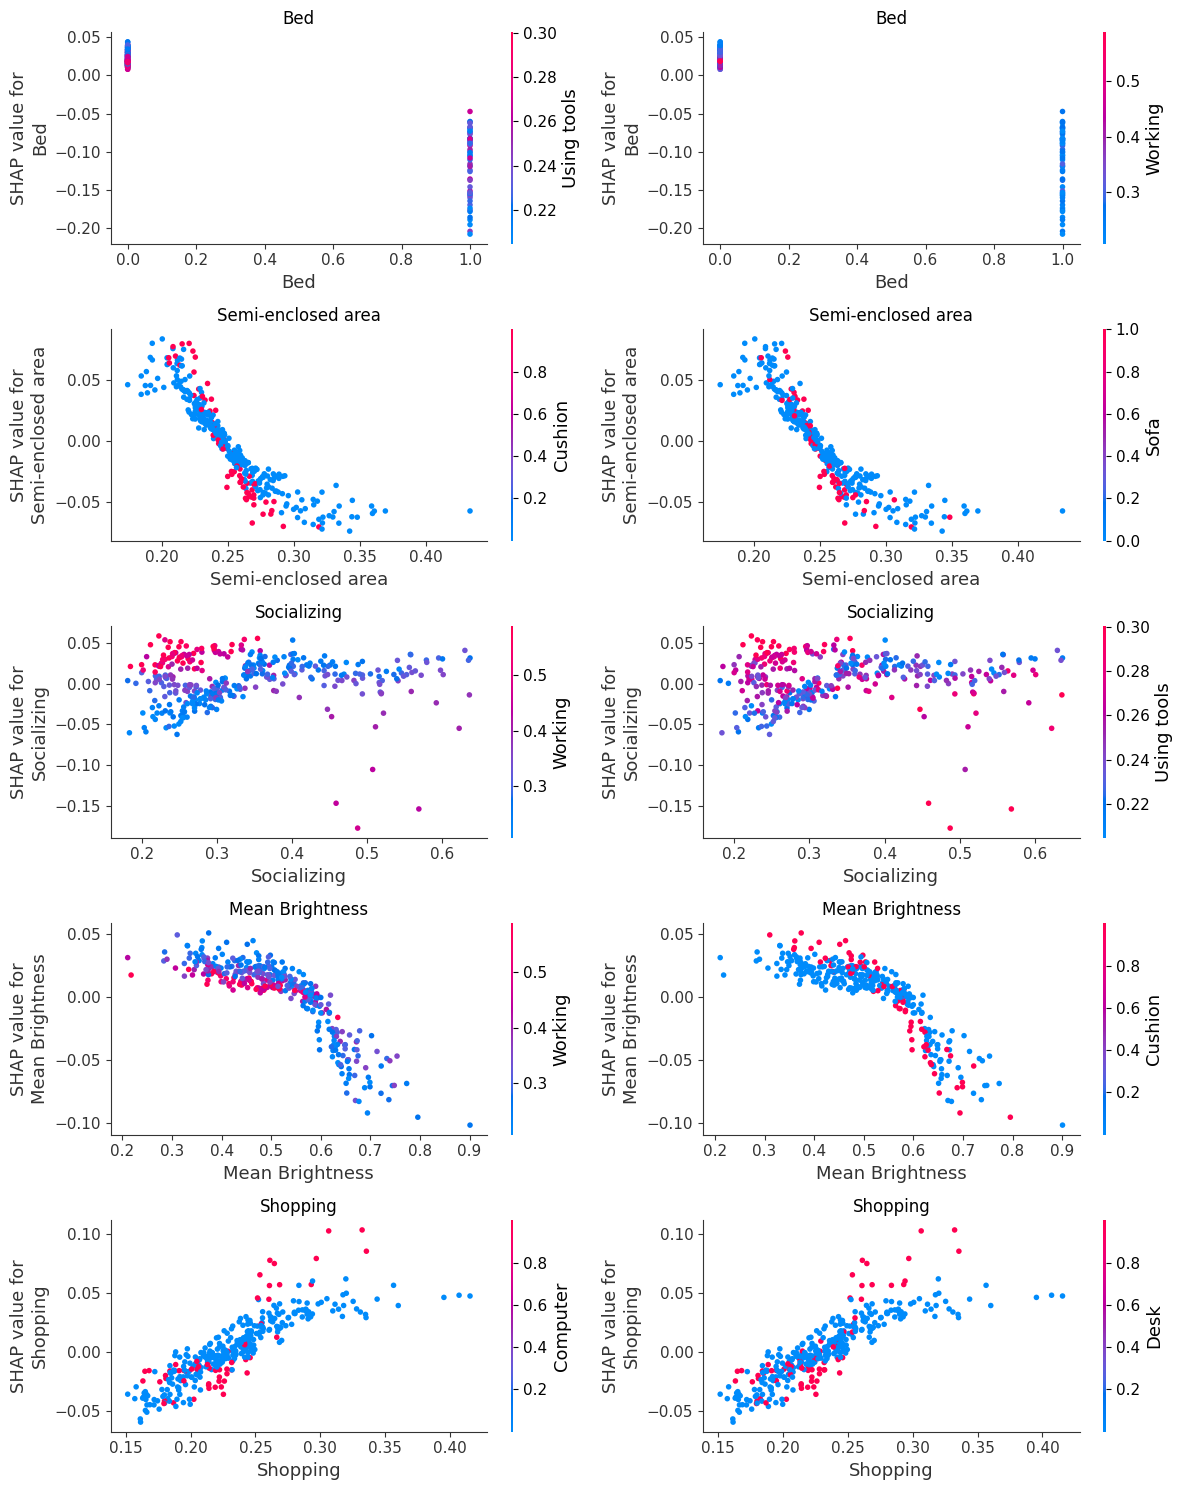

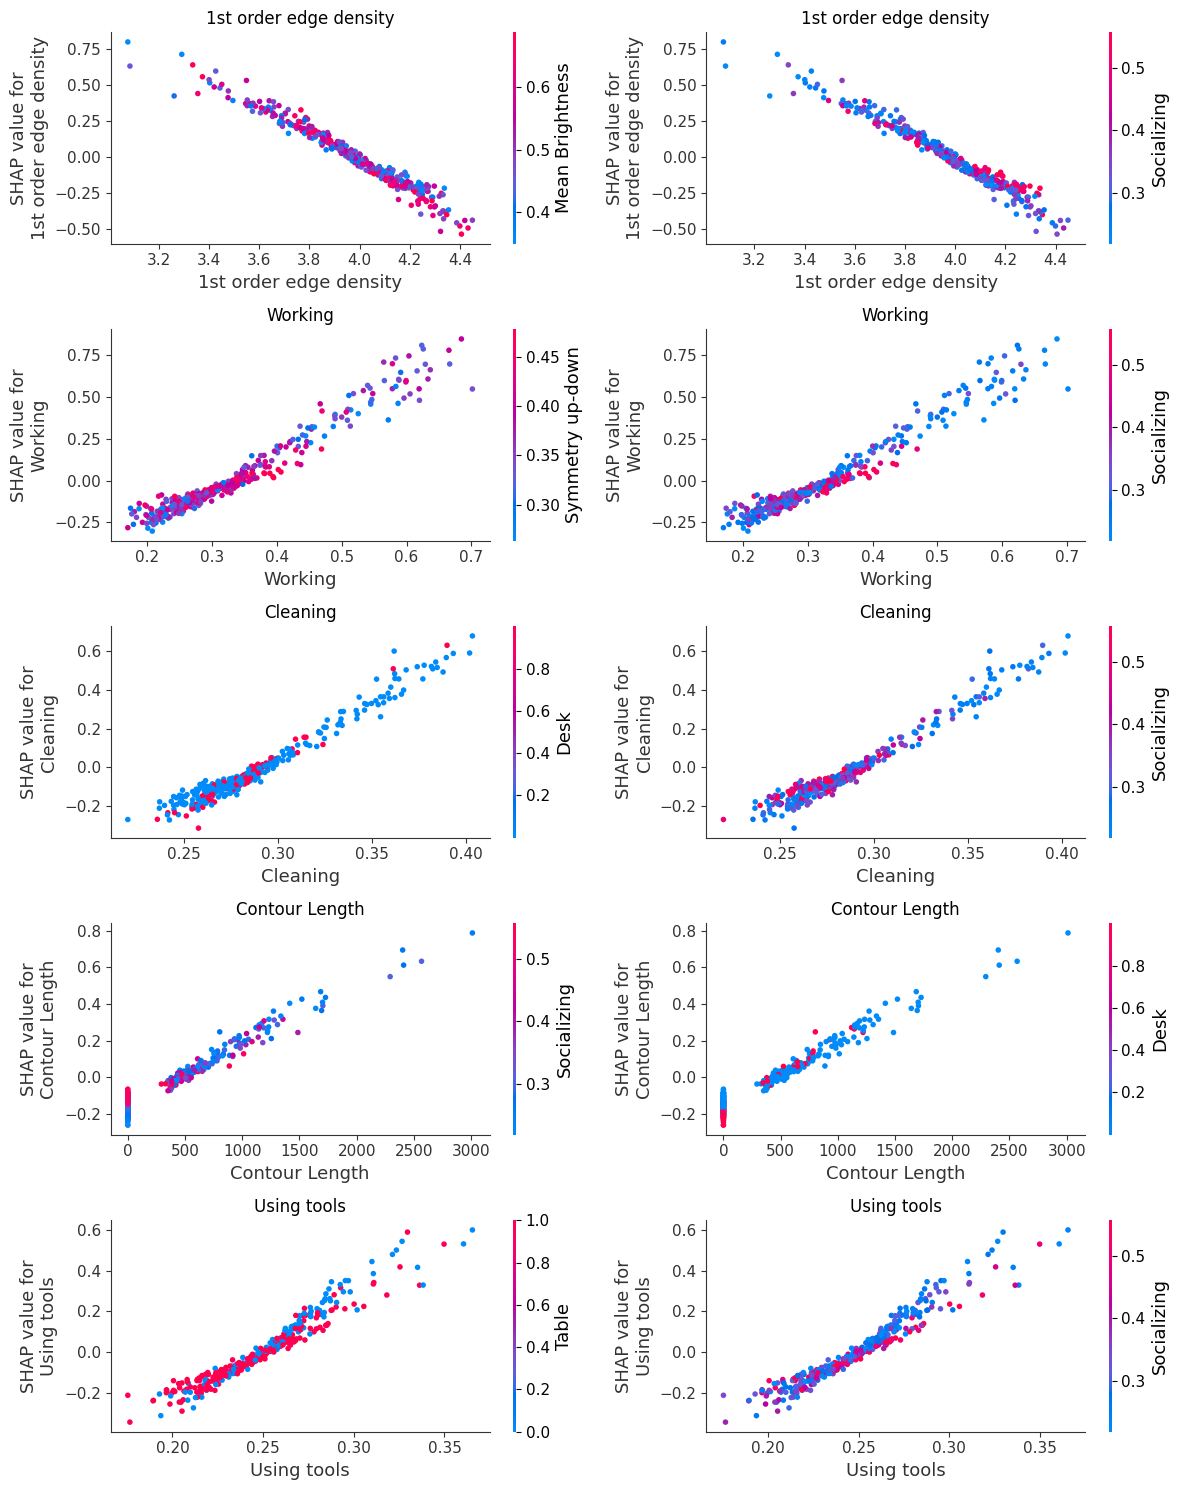

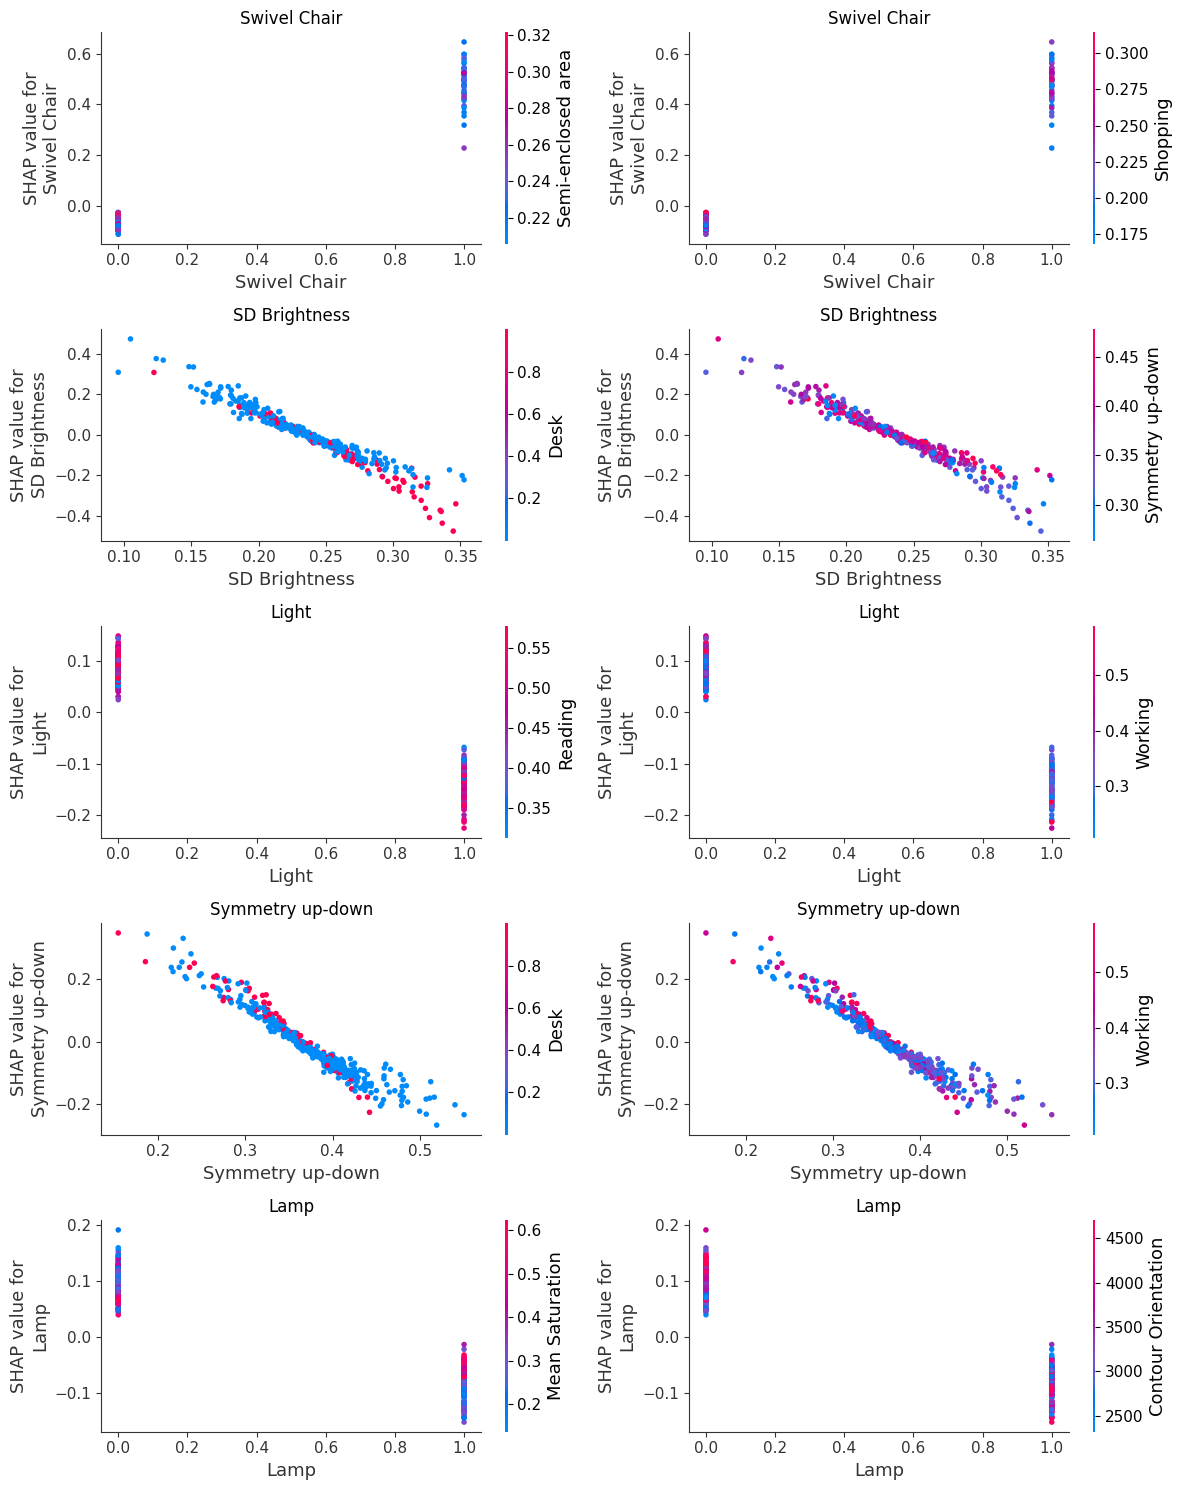

In [11]:
X_test_inverse = pd.DataFrame(scaler.inverse_transform(X_test), columns=X_test.columns)
fig_dir = "/home/fdeniz2/ML Paper/figures/"

dependence_with_interaction(X_test_inverse, shap_values_reg,    True, fig_dir + "tense_dependence_plot_regression.svg")
dependence_with_interaction(X_test_inverse, shap_values_forest, True, fig_dir + "tense_dependence_plot_forest.svg")
dependence_with_interaction(X_test_inverse, shap_values_dfnn,   True, fig_dir + "tense_dependence_plot_dfnn.svg")

### Combined Results

In [28]:
dcnn = pd.read_csv("/home/fdeniz2/models/results/model_performance_tense_dcnn.csv")
cdcnn = pd.read_csv("/home/fdeniz2/models/results/model_performance_tense_c_dcnn.csv")
dfnn = pd.read_csv("/home/fdeniz2/models/results/model_performance_tense_dfnn.csv")
model_performance_tense_lr = pd.read_csv("/home/fdeniz2/models/results/model_performance_tense_lr.csv")
model_performance_tense_rf = pd.read_csv("/home/fdeniz2/models/results/model_performance_tense_rf.csv")
all_results_tense = pd.concat([model_performance_tense_lr,model_performance_tense_rf,dfnn, dcnn, cdcnn])
all_results_tense.to_csv("/home/fdeniz2/models/results/all_results_tense.csv")

# Energetic Arousal

### Random Forest

In [29]:
from sklearn.pipeline import Pipeline

X = mean_data[mean_data.columns.difference(["image", "valence", "Unnamed: 0", "room_type", "approach", "tense", "energetic"])]
y = mean_data.energetic

param_distributions = {
    'forest__max_features': ['sqrt', 'log2', None, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9],
    'forest__min_samples_leaf': [1, 2, 3, 5, 10],
    'forest__min_impurity_decrease': [0.0, 0.01, 0.02, 0.05]
}

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("forest", RandomForestRegressor(n_jobs = -1, random_state=42))
])

search = RandomizedSearchCV(estimator=pipeline,param_distributions=param_distributions,  scoring='neg_mean_absolute_error', 
    n_jobs=-1,cv=repeated_k_fold,verbose=1,random_state = 42, n_iter = 10)

search.fit(X, y)

random_forest_energetic = search.best_estimator_
model_performance_energetic_rf, shap_valence_rf, feature_names = fit_models_cross_validation(X, y, random_forest_energetic, repeated_k_fold, shap.TreeExplainer, False, False)
model_performance_energetic_rf = to_dataframe_(model_performance_energetic_rf, "RF")
print(f"Mean model performance {model_performance_energetic_rf['Rsquared'].mean()}")
model_performance_energetic_rf.to_csv("./results/model_performance_energetic_rf.csv")
print("Results are saved")


Fitting 30 folds for each of 10 candidates, totalling 300 fits
Mean model performance 0.7867151985595943
Results are saved


### Linear

In [30]:
linear_regression = Pipeline([
    ("scaler", StandardScaler()),
    ("regression", LinearRegression())
])
model_performance_energetic_lr, shap_energetic_lr, feature_names = fit_models_cross_validation(X, y, LinearRegression(), repeated_k_fold, shap.LinearExplainer, True, False)
model_performance_energetic_lr = to_dataframe_(model_performance_energetic_lr, "LR")
model_performance_energetic_lr.to_csv("/home/fdeniz2/models/results/model_performance_energetic_lr.csv")
print(f"Mean model performance {model_performance_energetic_lr['Rsquared'].mean()}")
print("Results are saved")

Mean model performance 0.7936956519759425
Results are saved


### Shap

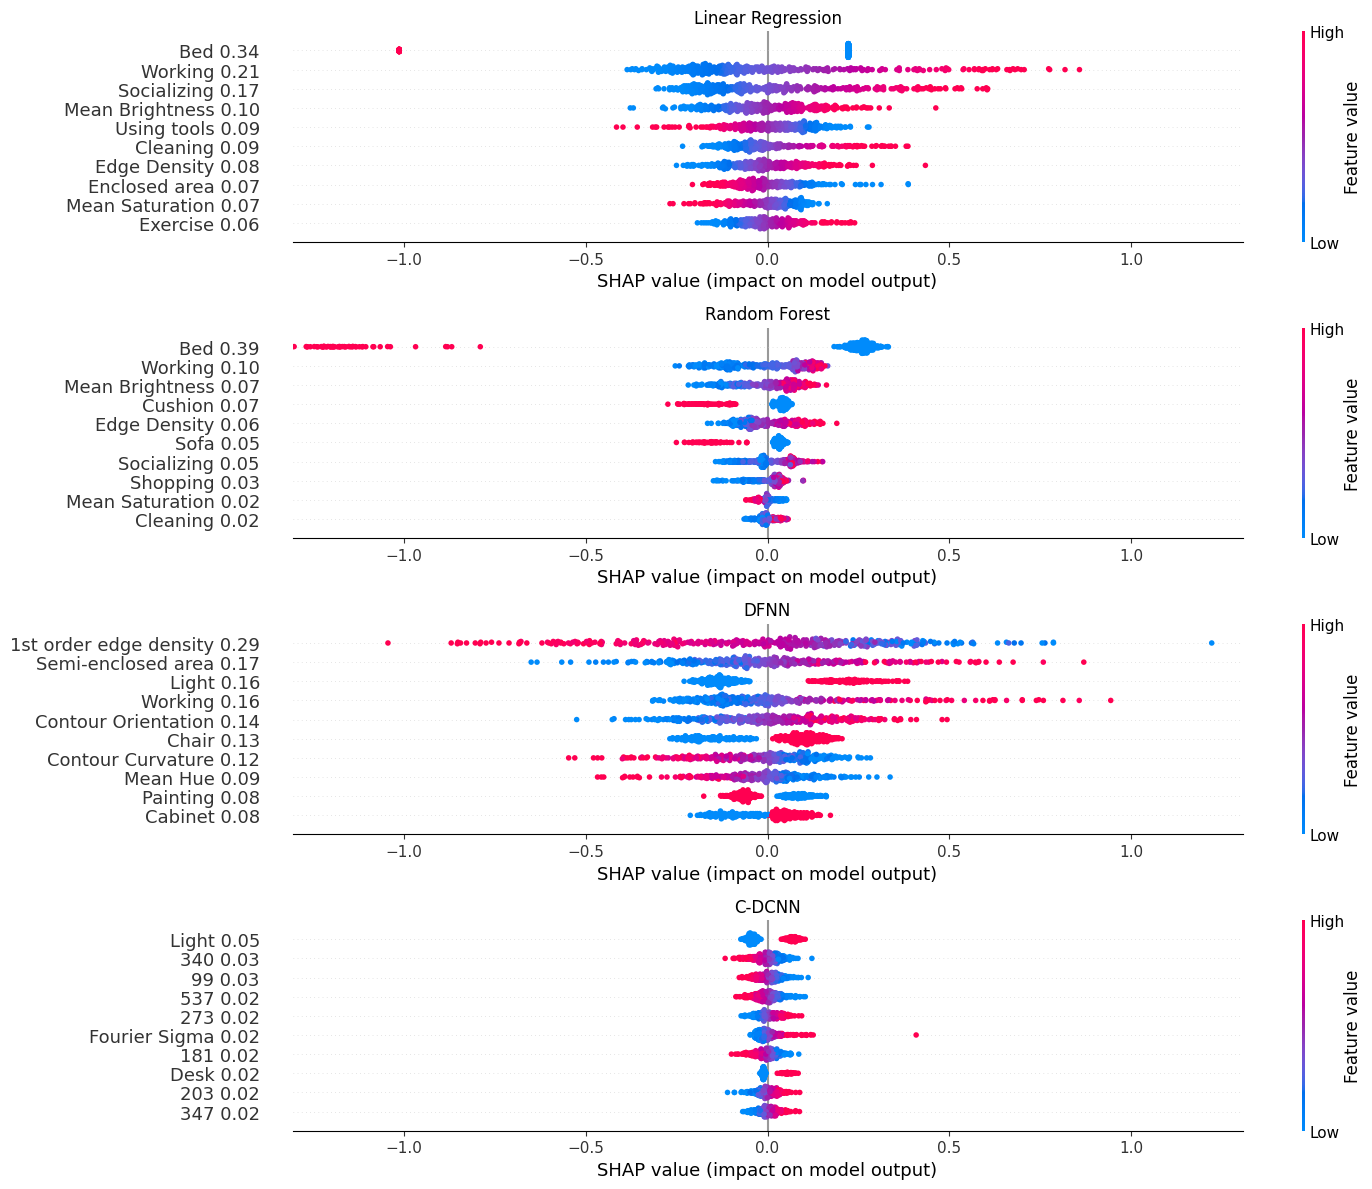

In [10]:
import importlib
import utils.shap_utils
importlib.reload(utils.shap_utils)
from utils.shap_utils import calculate_shap, shap_summary_plot_all_models

save_loc = "/home/fdeniz2/ML Paper/results/SHAP"
target = "energetic"
split = list(repeated_k_fold.split(mean_data))
index_val = 0 
train_idx, test_idx = split[index_val]

# Scale data based on train/test split
mean_data_scaled, _ = scale_fold_data(mean_data, train_idx, test_idx, mean_data[mean_data.columns.difference(["image", "valence", "Unnamed: 0", "room_type", "approach", "tense", "energetic"])].columns)
combined_outputs_scaled, _ = scale_fold_data(combined_outputs, train_idx, test_idx, combined_outputs[combined_outputs.columns.difference(["image", "valence", "Unnamed: 0", "room_type", "approach", "tense", "energetic"])].columns)

X = mean_data_scaled[mean_data_scaled.columns.difference(["image", "valence", "Unnamed: 0", "room_type", "approach", "tense", "energetic"])]
X_dcnn = combined_outputs_scaled[combined_outputs_scaled.columns.difference(["image", "valence", "Unnamed: 0", "room_type", "approach", "tense", "energetic"])]
y = mean_data_scaled[target]

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
_,X_test_combined = X_dcnn.iloc[train_idx], X_dcnn.iloc[test_idx]

feature_names = X_train.columns

if os.path.exists(os.path.join(save_loc, f"shap_{target}_linear.npy")):
    shap_values_reg = np.load(os.path.join(save_loc, f"shap_{target}_linear.npy"))
else:
    linear_regression = LinearRegression()
    linear_regression.fit(X_train, y_train) 
    explainer = shap.LinearExplainer(linear_regression, X_train) 
    shap_values_reg = explainer(X_test).values.squeeze()
    np.save(os.path.join(save_loc, f"shap_{target}_linear.npy"),shap_values_reg)

if os.path.exists(os.path.join(save_loc, f"shap_{target}_forest.npy")):
    shap_values_forest = np.load(os.path.join(save_loc, f"shap_{target}_forest.npy"))
else:
    random_forest = RandomForestRegressor(n_jobs = -1, random_state=42, min_samples_leaf = 5, max_features = 0.5, min_impurity_decrease = 0)
    random_forest.fit(X_train, y_train)
    forest_explainer = shap.TreeExplainer(random_forest, X_train)
    shap_values_forest = forest_explainer(X_test).values.squeeze()
    np.save(os.path.join(save_loc, f"shap_{target}_forest.npy"),shap_values_forest)

if os.path.exists(os.path.join(save_loc, f"shap_{target}_dfnn.npy")):
    shap_values_dfnn = np.load(os.path.join(save_loc, f"shap_{target}_dfnn.npy"))
else:
    train_dataloader, test_dataloader, dataset = load_dataset(load_csv, False, mean_data_scaled, target, train_idx, test_idx, batch_size = 360)
    feature_names = list(X.columns)
    dfnn = prediction_head(number_of_visual_features, 0.2).to(device)
    dfnn.load_state_dict(torch.load(f'/home/fdeniz2/ML Paper/models/DFNN/{target}_{index_val}.pth'))
    shap_values_dfnn, test_inputs, dfnn_explainer = calculate_shap(dfnn, train_dataloader, test_dataloader, feature_names, device)
    shap_values_dfnn = shap_values_dfnn.values.squeeze()
    np.save(os.path.join(save_loc, f"shap_{target}_dfnn.npy"),shap_values_dfnn)

if os.path.exists(os.path.join(save_loc, f"shap_{target}_dcnn.npy")):
    shap_values_dcnn = np.load(os.path.join(save_loc, f"shap_{target}_dcnn.npy"))
    feature_names_dcnn_combined = list(combined_outputs.columns.difference(["image", "valence", "Unnamed: 0", "room_type", "approach", "tense", "energetic"]))
else:
    train_dataloader, test_dataloader, dataset = load_dataset(load_csv, False, combined_outputs_scaled, target, train_idx, test_idx, batch_size = 360)
    feature_names_dcnn_combined = list(combined_outputs.columns.difference(["image", "valence", "Unnamed: 0", "room_type", "approach", "tense", "energetic"]))
    dcnn = prediction_head(drop_out_rate=0.5, n_features = 768+number_of_visual_features)
    dcnn = dcnn.to(device)
    dcnn.load_state_dict(torch.load(f'/home/fdeniz2/ML Paper/models/C-DCNN/{target}_{index_val}.pth'))
    shap_values_dcnn, test_inputs_dcnn, dcnn_explainer = calculate_shap(dcnn, train_dataloader, test_dataloader, feature_names_dcnn_combined, device)
    shap_values_dcnn = shap_values_dcnn.values.squeeze()
    np.save(os.path.join(save_loc, f"shap_{target}_dcnn.npy"),shap_values_dcnn)

shap_summary_plot_all_models(shap_values_reg, X_test, 
                             shap_values_forest, X_test,
                             shap_values_dfnn, X_test,
                             shap_values_dcnn, X_test_combined,
                             _, feature_names_dcnn_combined,
                             True, f"/home/fdeniz2/ML Paper/figures/{target}_importance.svg")

In [31]:
def plot_shap_all(shap_values, X, feature_names, model_name="Model",
                  top_n=None, row_height=0.28, save_path=None, show = False):
    mean_abs = np.abs(shap_values).mean(axis=0)
    order = np.argsort(mean_abs)[::-1]          # most important first
    if top_n is not None:
        order = order[:top_n]
    n = len(order)

    labels = [f"{index + 1}) {feature_names[i]}  {mean_abs[i]:.2f}" for index, i in enumerate(order)]

    plt.figure(figsize=(10, 10))
    shap.summary_plot(shap_values[:, order],X.iloc[:, order].values,feature_names=labels,max_display=n,       
        sort=False, show=False,plot_size=None)
    plt.title(model_name)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=100, bbox_inches="tight")
    if show == True:
        plt.show()
    else:
        plt.close()

plot_shap_all(shap_values_reg, X_test, feature_names, "LR",
              save_path=f"/home/fdeniz2/ML Paper/figures/{target}_lr_all.png")

plot_shap_all(shap_values_forest, X_test, feature_names, "RF",
              save_path=f"/home/fdeniz2/ML Paper/figures/{target}_rf_all.png")

plot_shap_all(shap_values_dfnn, X_test, feature_names, "DFNN",
              save_path=f"/home/fdeniz2/ML Paper/figures/{target}_dfnn_all.png")

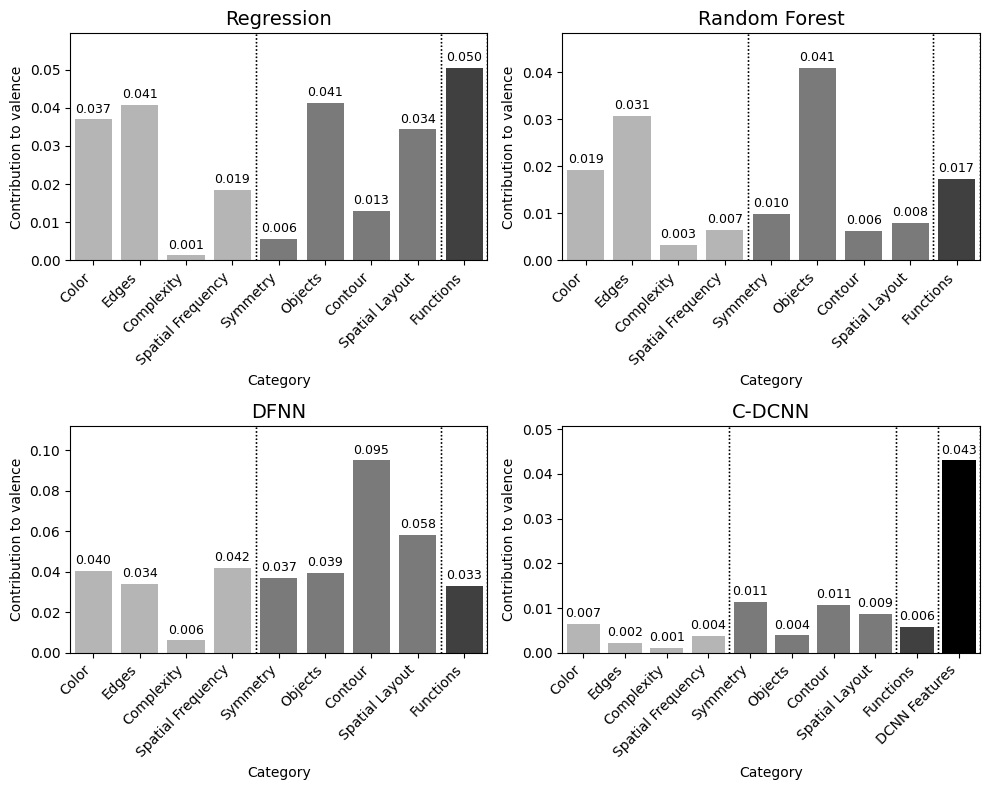

In [32]:
from utils.shap_utils import find_contribution, plot_contributions
importlib.reload(utils.shap_utils)

from utils.shap_utils import find_contribution, plot_contributions

contributions_reg, contributions_reg_group = find_contribution(shap_values_reg, feature_names)
contributions_forest, contributions_forest_group = find_contribution(shap_values_forest, feature_names)
contributions_dfnn, contributions_dfnn_group = find_contribution(shap_values_dfnn, feature_names)
contributions_dcnn, contributions_dcnn_group = find_contribution(shap_values_dcnn, feature_names, True)

fig = plt.figure(figsize=(10, 8))
gs = GridSpec(2, 2, figure=fig)

ax1 = fig.add_subplot(gs[0, 0])
ax1.set_title("Regression", fontsize=14)
plot_contributions(ax1, contributions_reg, contributions_reg_group)
ax1.set_xticklabels(["Color", "Edges", "Complexity", "Spatial Frequency", "Symmetry", "Objects", "Contour", "Spatial Layout", "Functions"], rotation=45, ha="right")
ax1.set_ylabel('Contribution to valence')

ax2 = fig.add_subplot(gs[0, 1])
ax2.set_title("Random Forest", fontsize=14)
plot_contributions(ax2, contributions_forest, contributions_forest_group)
ax2.set_xticklabels(["Color", "Edges", "Complexity", "Spatial Frequency", "Symmetry", "Objects", "Contour", "Spatial Layout", "Functions"], rotation=45, ha="right")
ax2.set_ylabel('Contribution to valence')

ax3 = fig.add_subplot(gs[1, 0])
ax3.set_title("DFNN", fontsize=14)
plot_contributions(ax3, contributions_dfnn, contributions_dfnn_group)
ax3.set_xticklabels(["Color", "Edges", "Complexity", "Spatial Frequency", "Symmetry", "Objects", "Contour", "Spatial Layout", "Functions"], rotation=45, ha="right")
ax3.set_ylabel('Contribution to valence')

ax4 = fig.add_subplot(gs[1, 1])
ax4.set_title("C-DCNN", fontsize=14)
plot_contributions(ax4, contributions_dcnn, contributions_dcnn_group, extra_label="DCNN Features")
ax4.set_xticklabels(["Color", "Edges", "Complexity", "Spatial Frequency", "Symmetry", "Objects", "Contour", "Spatial Layout", "Functions", "DCNN Features"], rotation=45, ha="right")
ax4.set_ylabel('Contribution to valence')

plt.tight_layout()
plt.savefig("/home/fdeniz2/ML Paper/figures/energetic_overall_importance.svg", format="svg")
plt.show()

In [33]:
expected_value = forest_explainer.expected_value
random_set = np.random.randint(0, 360, size=50)

fig, axes = plt.subplots(3, 1, figsize=(25, 20))
plt.sca(axes[0])  # Set current axis
shap.decision_plot(expected_value, shap_values_reg[random_set,:], X_test.columns,feature_display_range=slice(None, None, -1),show = False)
axes[0].set_title("Linear Regression")

plt.sca(axes[1])  # Set current axis
shap.decision_plot(expected_value, shap_values_forest[random_set,:], X_test.columns,feature_display_range=slice(None, None, -1),show = False)
axes[1].set_title("Random Forest")

plt.sca(axes[2])  # Set current axis
shap.decision_plot(expected_value, shap_values_dfnn[random_set,:], X_test.columns,feature_display_range=slice(None, None, -1),show = False)
axes[2].set_title("DFNN")

axes[0].tick_params(axis='y', labelsize=8)
axes[1].tick_params(axis='y', labelsize=8)
axes[2].tick_params(axis='y', labelsize=8)

plt.tight_layout()

plt.savefig("/home/fdeniz2/ML Paper/figures/energetic_decision_plot.svg", format = "svg")
plt.close()

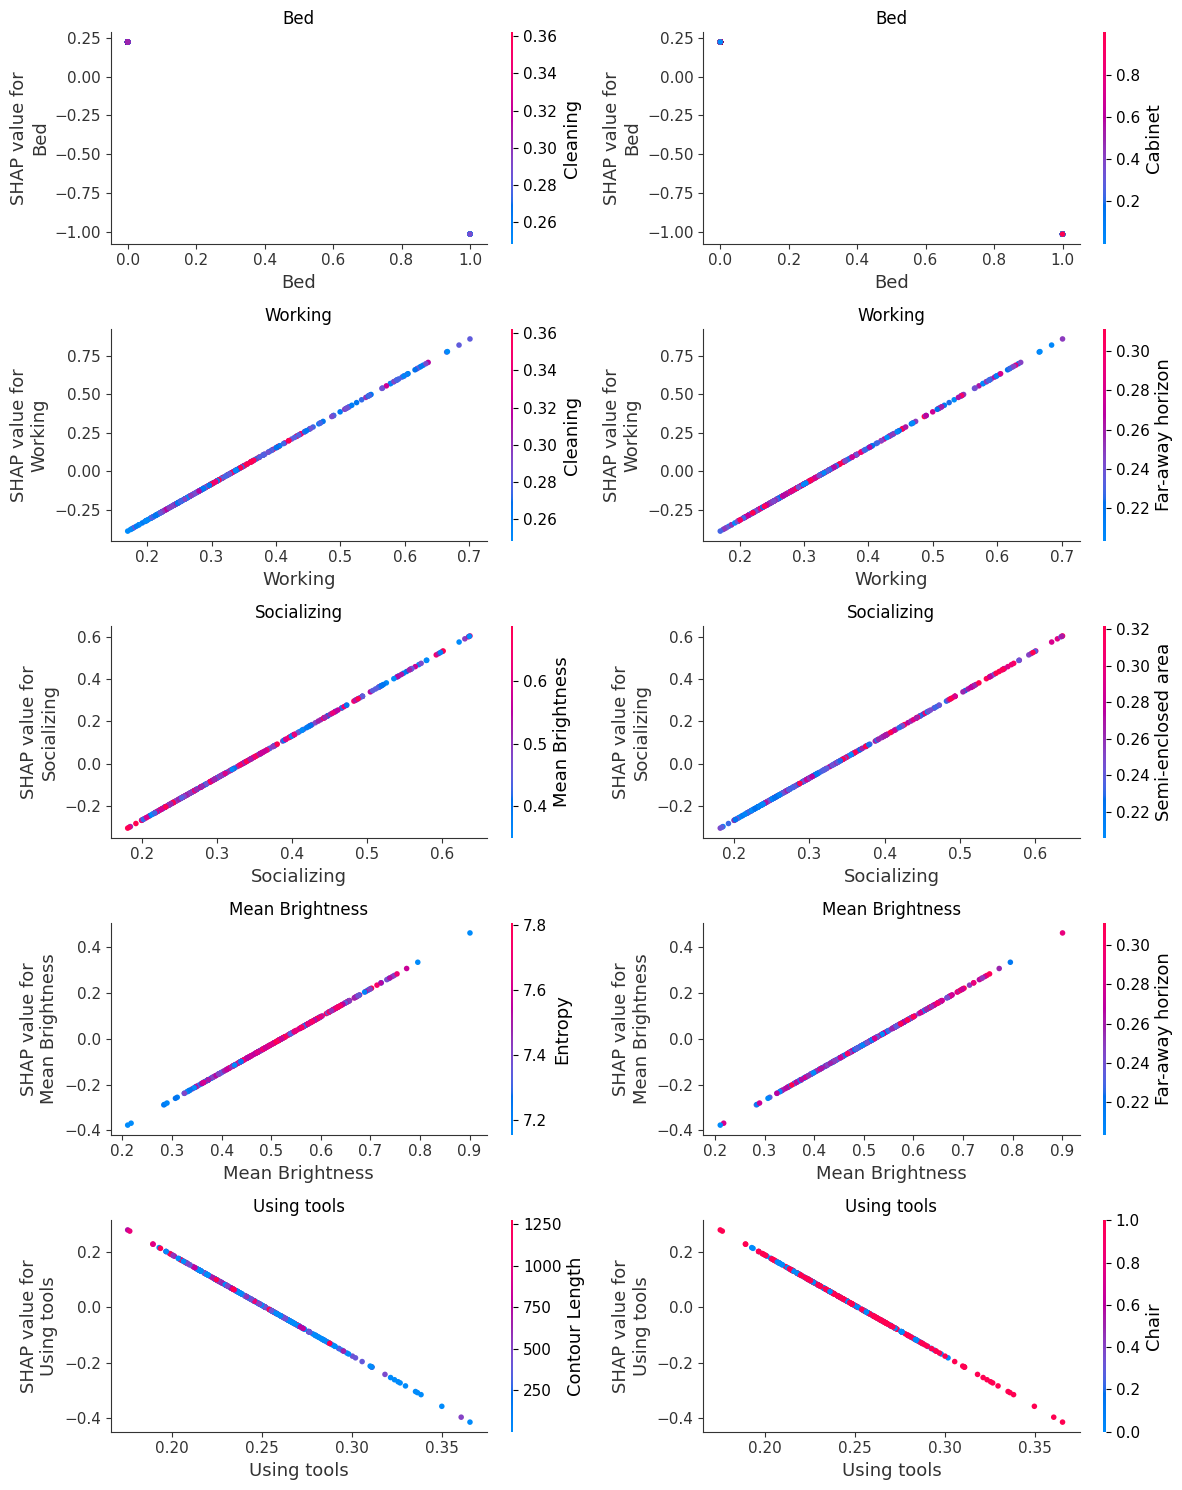

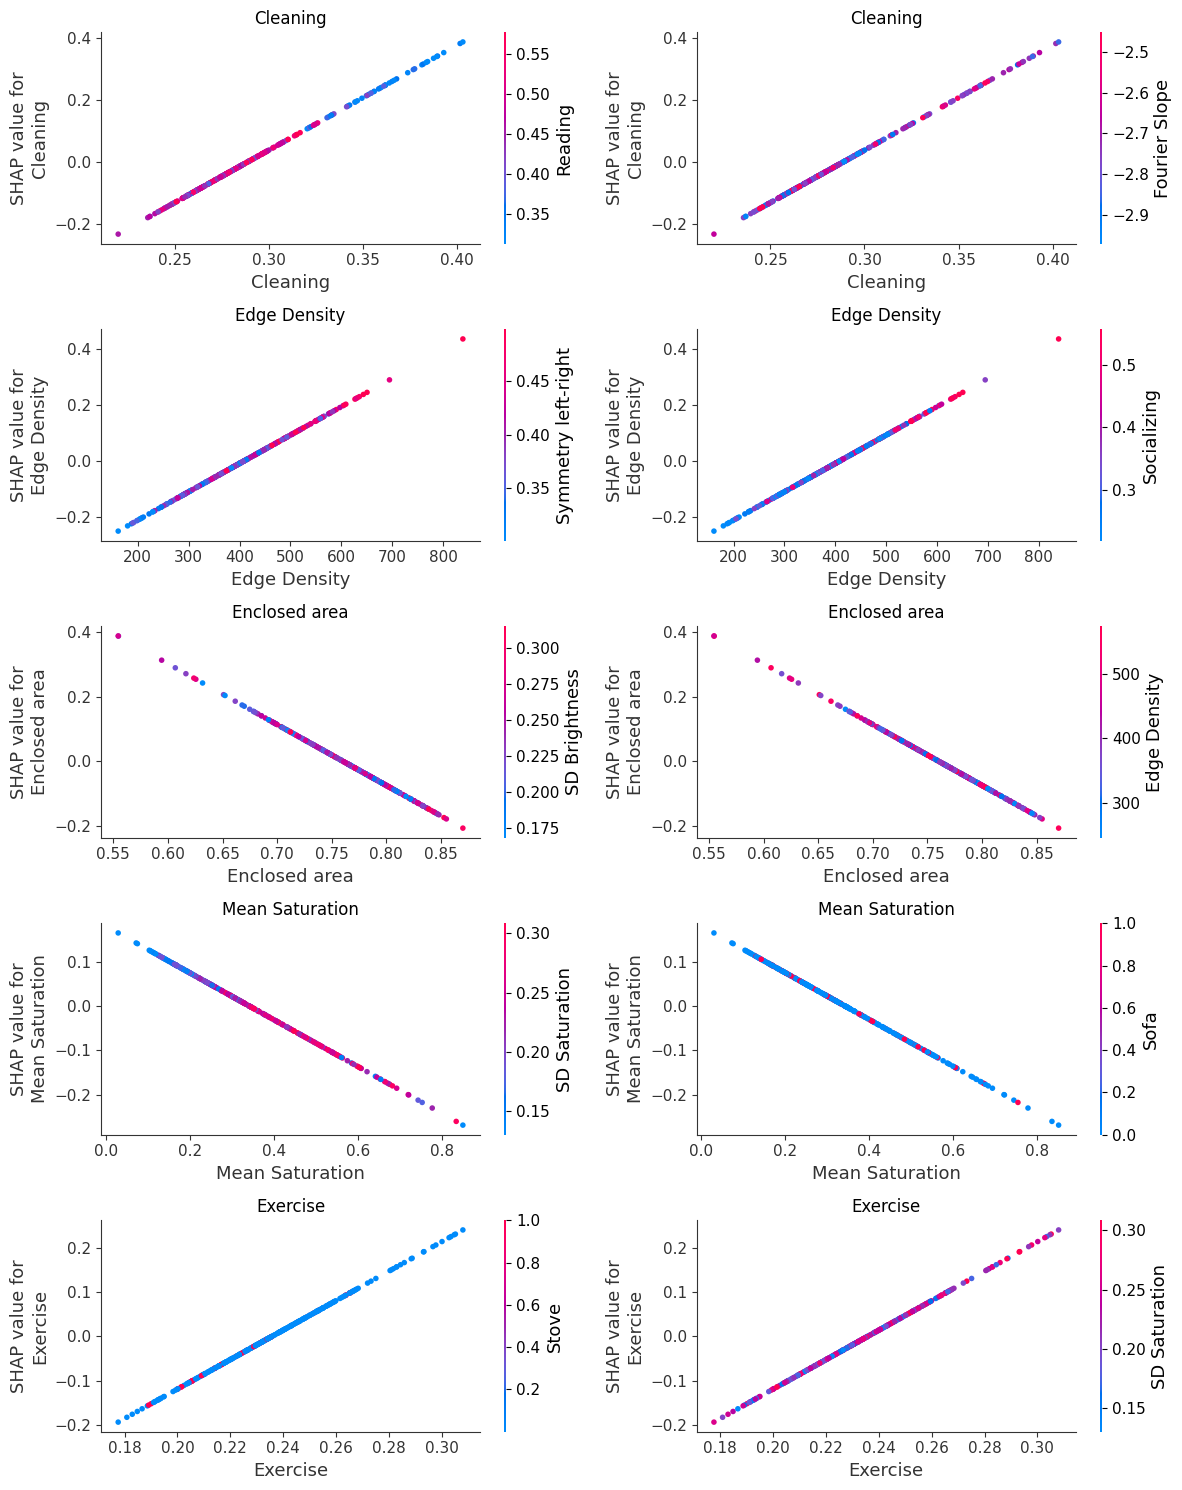

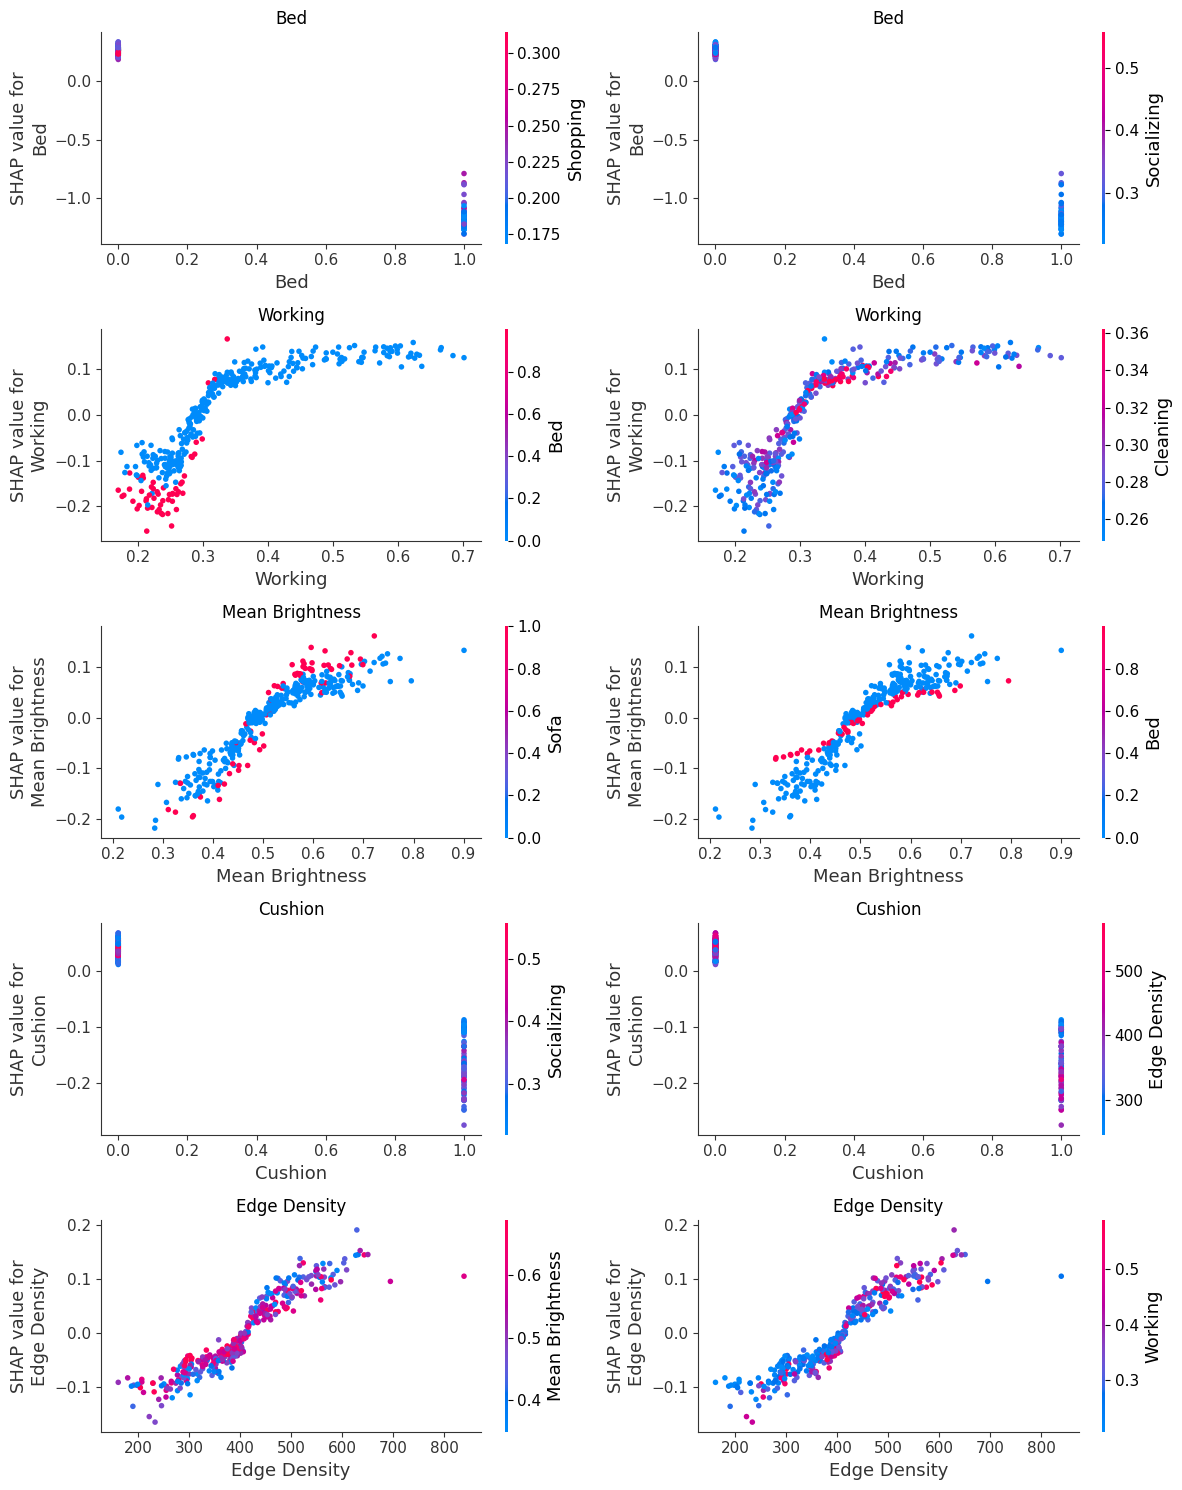

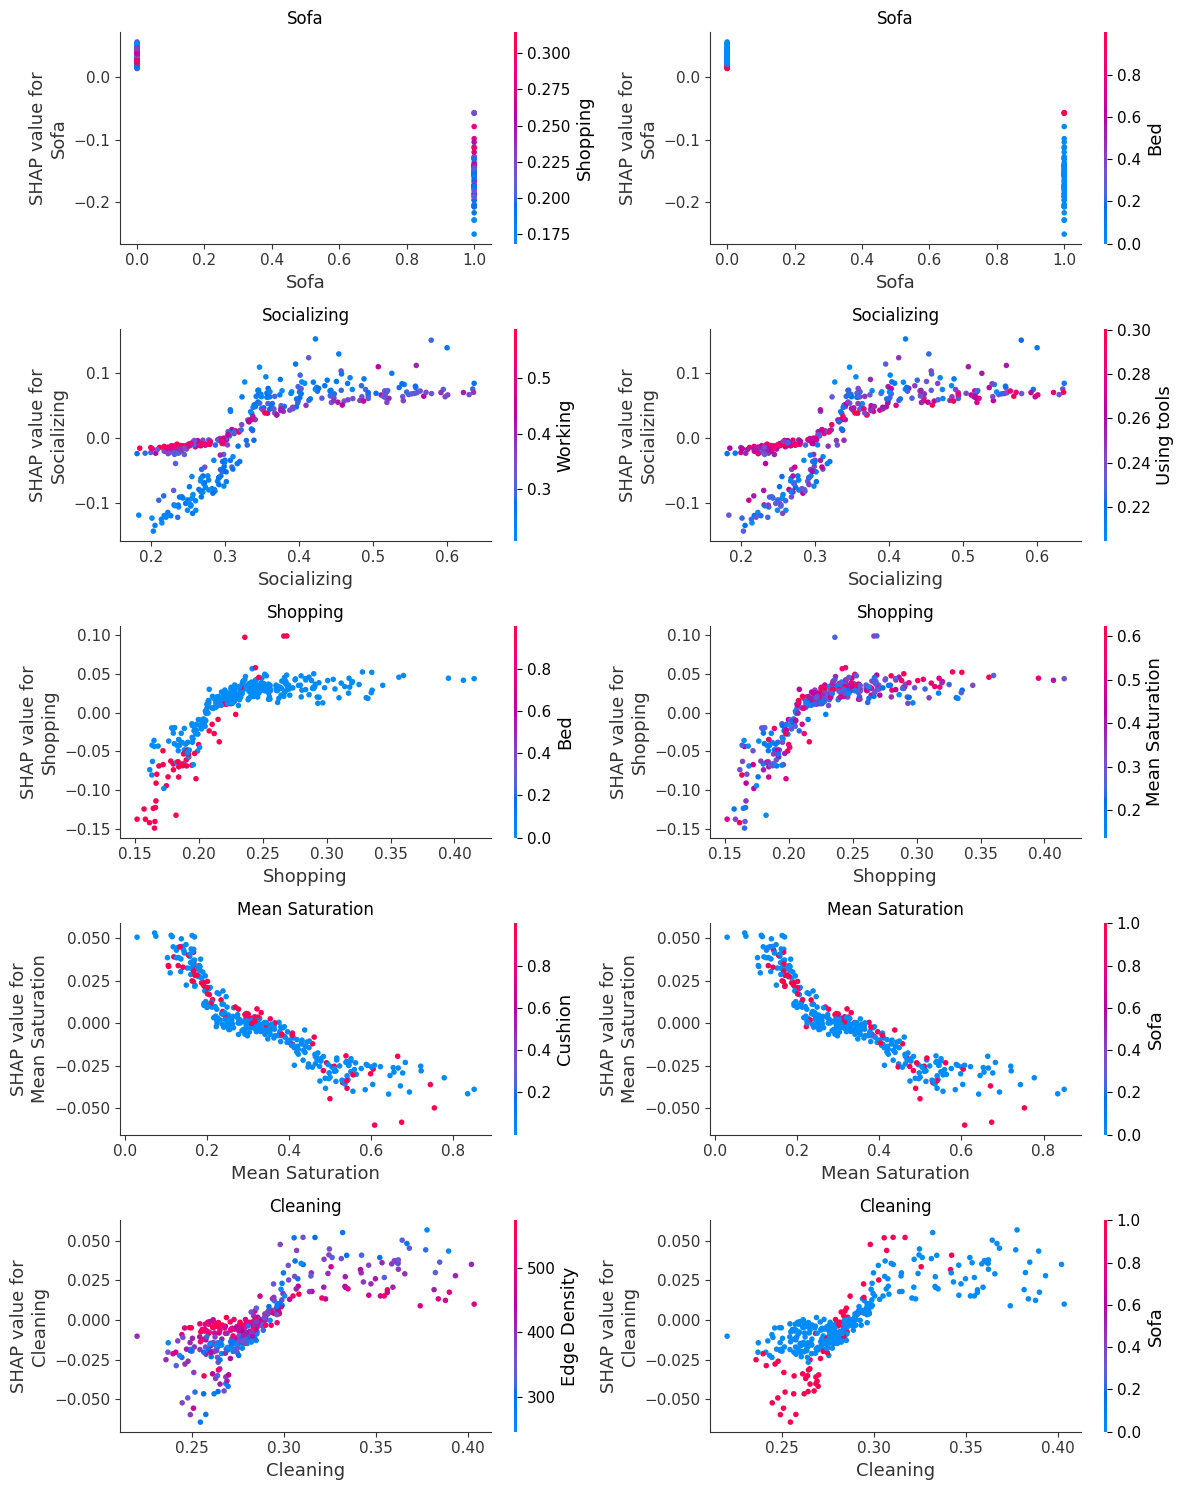

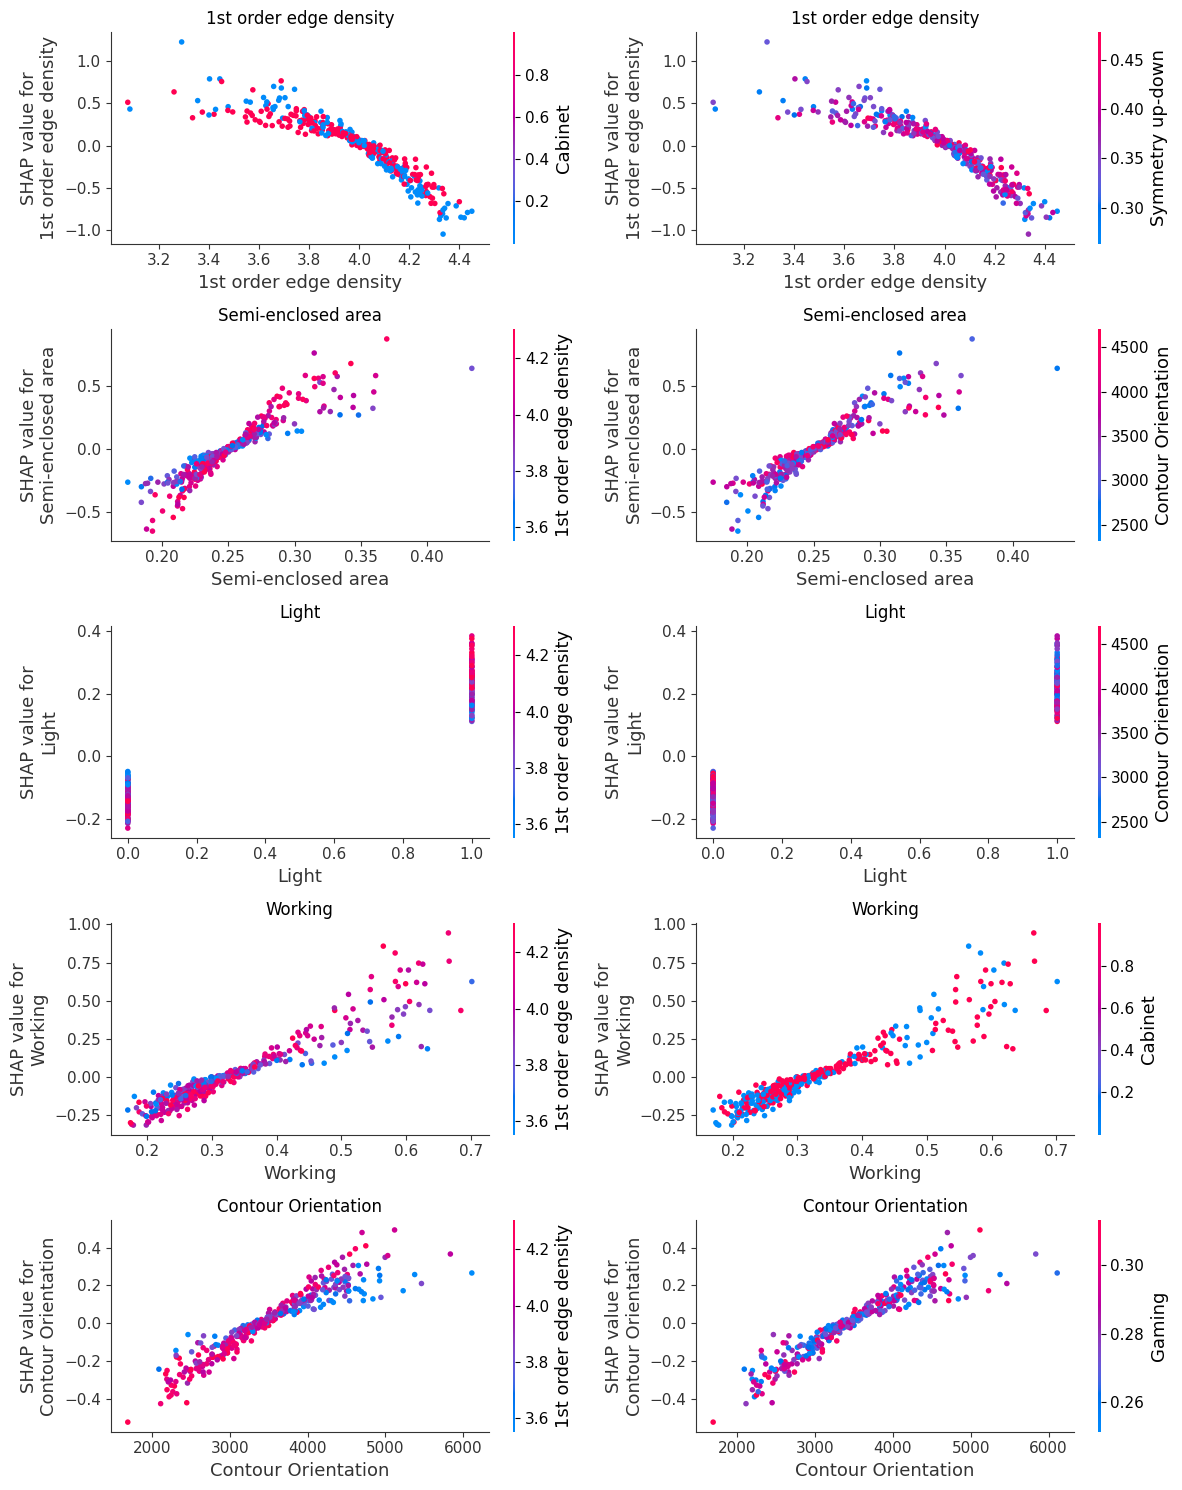

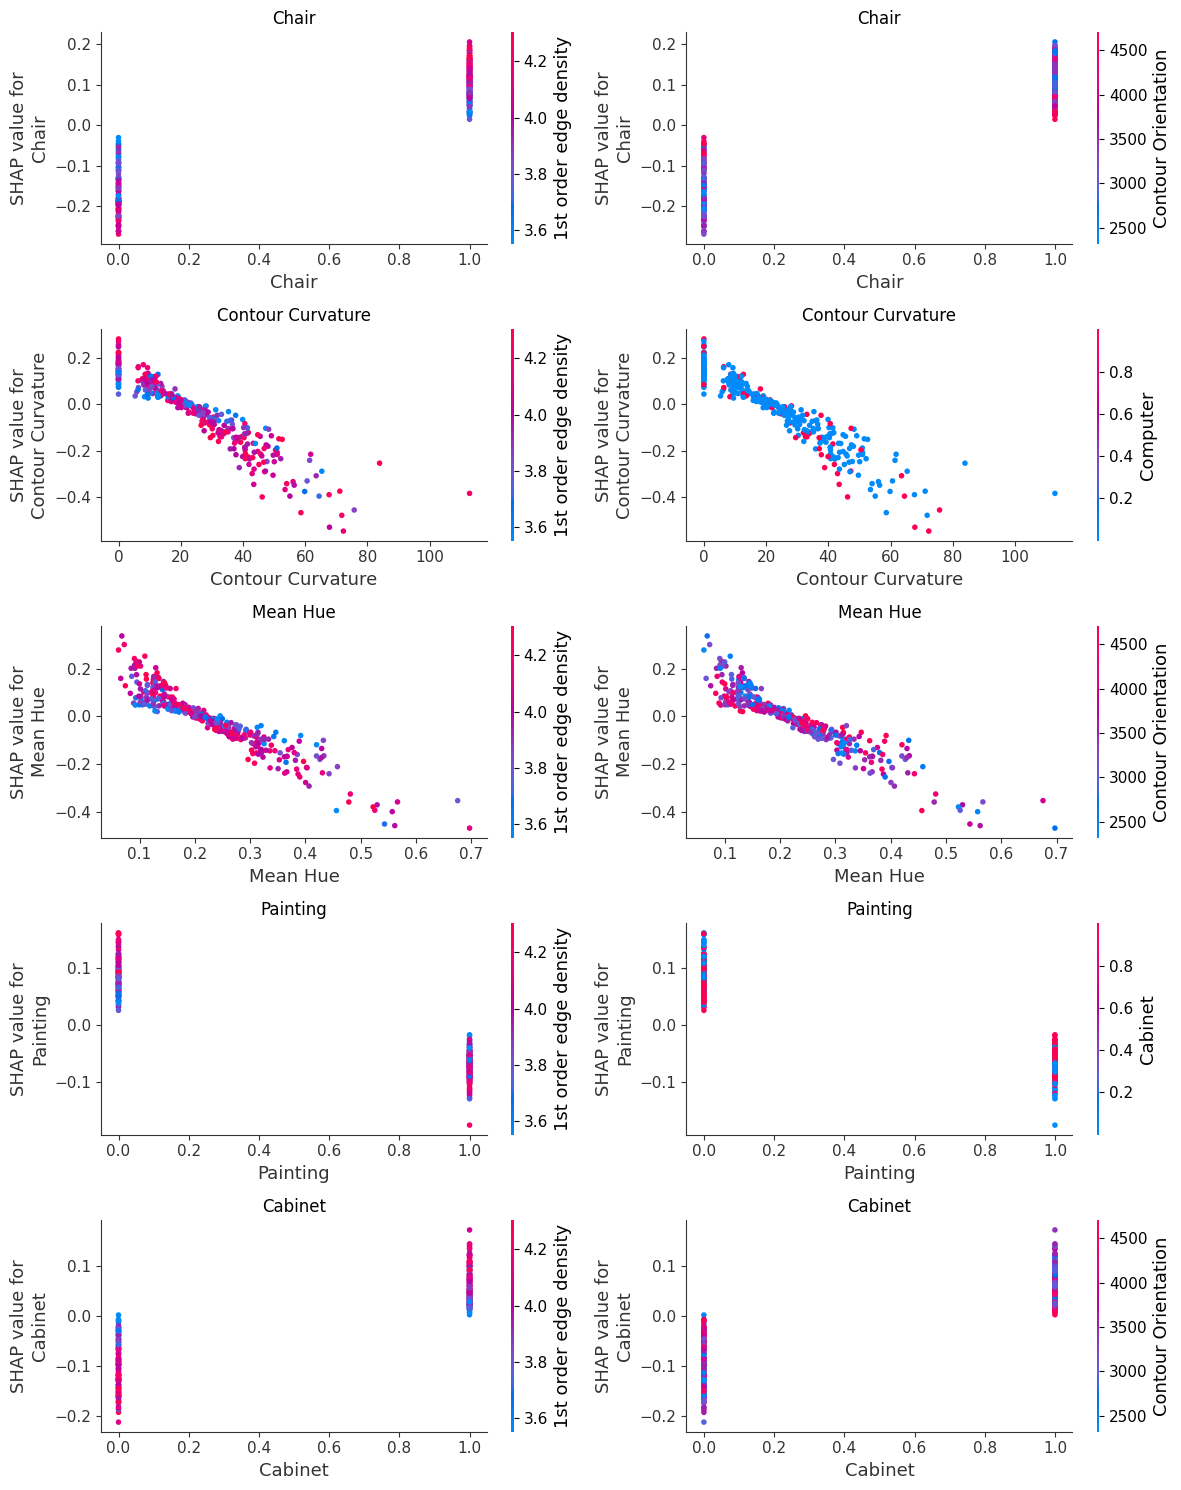

In [11]:
X_test_inverse = pd.DataFrame(scaler.inverse_transform(X_test), columns=X_test.columns)
fig_dir = "/home/fdeniz2/ML Paper/figures/"

dependence_with_interaction(X_test_inverse, shap_values_reg,    True, fig_dir + "energetic_dependence_plot_regression.svg")
dependence_with_interaction(X_test_inverse, shap_values_forest, True, fig_dir + "energetic_dependence_plot_forest.svg")
dependence_with_interaction(X_test_inverse, shap_values_dfnn,   True, fig_dir + "energetic_dependence_plot_dfnn.svg")

### Combined Results

In [35]:
dcnn = pd.read_csv("/home/fdeniz2/models/results/model_performance_energetic_dcnn.csv")
c_dcnn = pd.read_csv("/home/fdeniz2/models/results/model_performance_energetic_c_dcnn.csv")
dfnn = pd.read_csv("/home/fdeniz2/models/results/model_performance_energetic_dfnn.csv")
model_performance_energetic_lr = pd.read_csv("/home/fdeniz2/models/results/model_performance_energetic_lr.csv")
model_performance_energetic_rf = pd.read_csv("/home/fdeniz2/models/results/model_performance_energetic_rf.csv")
#combined_dcnn = None
all_results_energetic = pd.concat([model_performance_energetic_lr,model_performance_energetic_rf, dfnn, dcnn,c_dcnn])
all_results_energetic.to_csv("/home/fdeniz2/models/results/all_results_energetic.csv")